# Análise Exploratória de Dados: Envelhecimento Ativo no Brasil

## O que é este notebook?

Este documento apresenta uma análise completa sobre o **envelhecimento ativo** no Brasil, utilizando dados da Pesquisa Nacional de Saúde (PNS 2019). Aqui, transformamos dados complexos em insights práticos para orientar políticas públicas e ações sociais.

### Por que isso importa?

O Brasil está envelhecendo rapidamente. Em 2019, havia mais de 30 milhões de pessoas com 60 anos ou mais. Garantir que esses idosos tenham uma vida digna, saudável e participativa é um desafio nacional que exige dados precisos e ações direcionadas.

### O que vamos descobrir?

Ao longo desta análise, responderemos perguntas como:
- Como está a qualidade de vida dos idosos brasileiros?
- Quais estados (UFs) e regiões têm o índice mais baixo?
- Quais fatores influenciam o envelhecimento saudável?
- Existem grupos diferentes de idosos com necessidades distintas?

### Como funciona o Índice de Envelhecimento Ativo (AAI)?

Criamos um "termômetro" chamado AAI. Hoje ele é a média de duas notas de 0 a 1:
1. **Capacidade funcional**: dificuldade para comer, tomar banho, se vestir, fazer compras e ir ao médico sozinho
2. **Saúde**: autoavaliação de saúde, número de doenças crônicas e a própria capacidade funcional

Escolaridade, renda e acesso a serviços são calculados no caminho, mas não entram no índice. A PNS não pergunta a cada idoso se ele usa internet ou celular, então não há nota de participação digital.

### Nossa abordagem rigorosa

Usamos técnicas estatísticas avançadas para garantir que os resultados representem toda a população idosa brasileira, não apenas as pessoas entrevistadas. Isso inclui:
- **Pesos amostrais**: Para corrigir diferenças na probabilidade de seleção
- **Intervalos de confiança por bootstrap**: sorteiam pessoas; ignoram os estratos e as UPAs da PNS, então o intervalo real é mais largo

---

*Este notebook foi desenvolvido para ser acessível a gestores públicos, profissionais de saúde, pesquisadores e qualquer pessoa interessada em melhorar a qualidade de vida dos idosos brasileiros.*

In [1]:
import pandas as pd

df = pd.read_csv("data/processed/pns_2019_pandas.csv")    
df.head(5)

,uf,estrato,upa,num_domicilio,num_morador,regiao,peso_amostral,idade,num_pessoas_domicilio,mora_sozinho,...,ajuda_adl,ajuda_iadl,vacina_influenza,queda_12m,atividade_fisica,dificuldade_vestir,dificuldade_banho,dificuldade_alimentar,dificuldade_compras,dificuldade_medico
0,Rondônia,1110011,110000016,1,2,Norte,NaN,69,6,Não,...,Não,Não,Sim,Não,NaN,Tem pequena dificuldade,Não tem dificuldade,Não tem dificuldade,Não tem dificuldade,Tem pequena dificuldade
1,Rondônia,1110011,110000016,3,2,Norte,NaN,78,8,Não,...,Não,Sim,Sim,Sim,NaN,Não tem dificuldade,Não tem dificuldade,Não tem dificuldade,Não tem dificuldade,Não consegue
2,Rondônia,1110011,110000016,6,1,Norte,117.758255,81,1,Sim,...,Sim,Sim,Não,Sim,Não,Tem pequena dificuldade,Tem pequena dificuldade,Não consegue,Não consegue,Não consegue
3,Rondônia,1110011,110000016,10,1,Norte,117.758255,81,1,Sim,...,NaN,Não,Não,Não,Não,Não tem dificuldade,Não tem dificuldade,Não tem dificuldade,Não tem dificuldade,Tem pequena dificuldade
4,Rondônia,1110011,110000016,15,1,Norte,NaN,72,5,Não,...,Não,Sim,Não,Não,NaN,Tem pequena dificuldade,Tem pequena dificuldade,Tem pequena dificuldade,Não tem dificuldade,Tem pequena dificuldade


# Análise Avançada do Índice de Envelhecimento Ativo (AAI) - PNS 2019

Este notebook realiza uma análise completa dos dados da Pesquisa Nacional de Saúde (PNS 2019) para construir e validar o Índice de Envelhecimento Ativo (AAI) no Brasil. 

**Objetivos principais:**
- Construir um índice multidimensional de envelhecimento ativo
- Comparar UFs e regiões
- Analisar desigualdades por subgrupos populacionais
- Desenvolver modelos preditivos de vulnerabilidade

**Metodologia:**
- Análise survey-aware com pesos amostrais
- Intervalos de confiança via bootstrap
- Agregação por UF com controle de qualidade
- Modelagem preditiva avaliada em pessoas separadas para teste

**Outputs esperados:**
- Scores por UF com intervalos de confiança
- Perfis de envelhecimento via clustering
- Drivers de vulnerabilidade identificados
- Policy brief automatizado
- Visualizações e datasets processados

In [2]:
print("Colunas disponíveis no df:")
print(df.columns.tolist())

Colunas disponíveis no df:
['uf', 'estrato', 'upa', 'num_domicilio', 'num_morador', 'regiao', 'peso_amostral', 'idade', 'num_pessoas_domicilio', 'mora_sozinho', 'nivel_instrucao', 'renda_percapita', 'peso_kg', 'altura_m', 'imc', 'num_medicamentos', 'consulta_12m', 'multimorbidity_count', 'multimorb_cat', 'adl_score', 'iadl_score', 'functional_raw', 'functional_score', 'dependencia_SUS', 'cobertura_influenza', 'autoav_z', 'multimorb_z', 'functional_z', 'health_score_raw', 'health_score', 'area_urbana', 'tipo_area', 'sexo', 'raca_cor', 'estado_civil', 'situacao_ocupacional', 'autoavaliacao_saude', 'atendimento_sus', 'fumante_atual', 'hipertensao', 'diabetes', 'doenca_cardiaca', 'avc', 'asma', 'doenca_pulmonar', 'cancer', 'depressao_diag', 'possui_plano_saude', 'internacao_12m', 'ajuda_adl', 'ajuda_iadl', 'vacina_influenza', 'queda_12m', 'atividade_fisica', 'dificuldade_vestir', 'dificuldade_banho', 'dificuldade_alimentar', 'dificuldade_compras', 'dificuldade_medico']


In [3]:
# quero ver todas as colunas sem supressao visual
pd.set_option('display.max_columns', None)
df.head(5)

,uf,estrato,upa,num_domicilio,num_morador,regiao,peso_amostral,idade,num_pessoas_domicilio,mora_sozinho,nivel_instrucao,renda_percapita,peso_kg,altura_m,imc,num_medicamentos,consulta_12m,multimorbidity_count,multimorb_cat,adl_score,iadl_score,functional_raw,functional_score,dependencia_SUS,cobertura_influenza,autoav_z,multimorb_z,functional_z,health_score_raw,health_score,area_urbana,tipo_area,sexo,raca_cor,estado_civil,situacao_ocupacional,autoavaliacao_saude,atendimento_sus,fumante_atual,hipertensao,diabetes,doenca_cardiaca,avc,asma,doenca_pulmonar,cancer,depressao_diag,possui_plano_saude,internacao_12m,ajuda_adl,ajuda_iadl,vacina_influenza,queda_12m,atividade_fisica,dificuldade_vestir,dificuldade_banho,dificuldade_alimentar,dificuldade_compras,dificuldade_medico
0,Rondônia,1110011,110000016,1,2,Norte,NaN,69,6,Não,1,350.0,NaN,NaN,NaN,2.0,Sim,NaN,NaN,1,1,2,0.866667,0.0,1.0,NaN,NaN,-0.187726,NaN,NaN,Urbano,Capital,Homem,Parda,Casado(a),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Não,Não,Não,Não,Sim,Não,NaN,Tem pequena dificuldade,Não tem dificuldade,Não tem dificuldade,Não tem dificuldade,Tem pequena dificuldade
1,Rondônia,1110011,110000016,3,2,Norte,NaN,78,8,Não,2,500.0,NaN,NaN,NaN,3.0,Sim,NaN,NaN,0,3,3,0.800000,0.0,1.0,NaN,NaN,-0.522010,NaN,NaN,Urbano,Capital,Mulher,Parda,Solteiro(a),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Não,Não,Não,Sim,Sim,Sim,NaN,Não tem dificuldade,Não tem dificuldade,Não tem dificuldade,Não tem dificuldade,Não consegue
2,Rondônia,1110011,110000016,6,1,Norte,117.758255,81,1,Sim,2,998.0,81.0,1.74,26.753864,2.0,Sim,1.0,1,5,6,11,0.266667,0.0,0.0,1.624599,-0.134573,-3.196276,-4.553629,0.416197,Urbano,Capital,Homem,Parda,Solteiro(a),NaN,Ruim,NaN,Não,Sim,Não,Não,Não,Não,Não,Não,Não,Não,Não,Sim,Sim,Não,Sim,Não,Tem pequena dificuldade,Tem pequena dificuldade,Não consegue,Não consegue,Não consegue
3,Rondônia,1110011,110000016,10,1,Norte,117.758255,81,1,Sim,2,1398.0,75.0,1.62,28.577961,3.0,Sim,2.0,2,0,1,1,0.933333,0.0,0.0,0.445638,0.826942,0.146557,-0.625810,0.750755,Urbano,Capital,Homem,Parda,Separado(a) ou divorciado(a),NaN,Regular,NaN,Não,Sim,Sim,Não,Não,Não,Não,Não,Não,Não,Não,NaN,Não,Não,Não,Não,Não tem dificuldade,Não tem dificuldade,Não tem dificuldade,Não tem dificuldade,Tem pequena dificuldade
4,Rondônia,1110011,110000016,15,1,Norte,NaN,72,5,Não,1,200.0,NaN,NaN,NaN,1.0,Sim,NaN,NaN,3,1,4,0.733333,0.0,0.0,NaN,NaN,-0.856293,NaN,NaN,Urbano,Capital,Mulher,Parda,Viúvo(a),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Não,Não,Não,Sim,Não,Não,NaN,Tem pequena dificuldade,Tem pequena dificuldade,Tem pequena dificuldade,Não tem dificuldade,Tem pequena dificuldade


In [4]:
# ===============================================================================
# ANÁLISE AVANÇADA DO ÍNDICE DE ENVELHECIMENTO ATIVO (AAI)
# PNS 2019 - Versão Corrigida e Metodologicamente Robusta
# ===============================================================================
# Autor: Análise Senior - Metodologia Survey-Aware
# Data: Outubro 2024
# Objetivo: AAI por UF e por grupo, com peso amostral
# ===============================================================================
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, confusion_matrix
from sklearn.impute import SimpleImputer
import warnings
warnings.filterwarnings('ignore')

# Pacotes opcionais
try:
    import shap
    SHAP_AVAILABLE = True
except:
    SHAP_AVAILABLE = False
    print(" SHAP não disponível (instale: shap)")

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
plt.style.use('seaborn-v0_8-whitegrid')

print("="*80)
print("BIBLIOTECAS CARREGADAS COM SUCESSO")
print("="*80)

BIBLIOTECAS CARREGADAS COM SUCESSO


In [5]:
# ===============================================================================
# SEÇÃO 1: CONFIGURAÇÃO E CARREGAMENTO
# ===============================================================================

# 🔧 AJUSTE OS CAMINHOS AQUI
DATA_PATH = "data/processed/pns_2019_pandas.csv"
OUTPUT_DIR = Path("./outputs_aai")
OUTPUT_DIR.mkdir(exist_ok=True)

# Configurações metodológicas
MIN_N = 30            # Mínimo de observações para uma estimativa por UF ser considerada confiável
N_BOOTSTRAP = 500     # Iterações para CIs
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print(f"\nCarregando dados de: {DATA_PATH}")
try:
    df = pd.read_csv(DATA_PATH, low_memory=False)
    print(f"Dataset carregado: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
except FileNotFoundError:
    print("Erro: Arquivo não encontrado. Ajuste DATA_PATH")
    raise


Carregando dados de: data/processed/pns_2019_pandas.csv


Dataset carregado: 43,554 linhas × 59 colunas


In [6]:
# ===============================================================================
# SEÇÃO 2: PADRONIZAÇÃO DE VARIÁVEIS CRÍTICAS
# ===============================================================================

print("\n" + "="*80)
print(" PADRONIZAÇÃO DE VARIÁVEIS")
print("="*80)

WEIGHT_COL = None
for col_name in ['peso', 'peso_amostral', 'peso_exp', 'weight']:
    if col_name in df.columns:
        WEIGHT_COL = col_name
        print(f"Coluna de peso identificada: '{WEIGHT_COL}'")
        break

if WEIGHT_COL is None:
    raise SystemExit("Erro critico: Coluna de peso não encontrada. Estimativas não-ponderadas são invalidas.")

# Validar variáveis essenciais
essential_vars = {
    'idade': 'Idade do indivíduo',
    'uf': 'Unidade Federativa',
    'estrato': 'Estrato amostral',
    'upa': 'Unidade primária de amostragem'
}

print("\nValidação de variáveis essenciais:")
missing_essentials = []
for var, desc in essential_vars.items():
    if var in df.columns:
        print(f"  ✓ {var:12s} - {desc}")
    else:
        print(f"  ✗ {var:12s} - {desc} [FALTANDO]")
        missing_essentials.append(var)

if missing_essentials:
    print(f"\nAtenção: Variáveis ausentes podem limitar análises: {missing_essentials}")


 PADRONIZAÇÃO DE VARIÁVEIS
Coluna de peso identificada: 'peso_amostral'

Validação de variáveis essenciais:
  ✓ idade        - Idade do indivíduo
  ✓ uf           - Unidade Federativa
  ✓ estrato      - Estrato amostral
  ✓ upa          - Unidade primária de amostragem


In [7]:
# A PNS pública não identifica o município da pessoa: os 6 primeiros dígitos da UPA
# não são um código de município do IBGE. Por isso a análise geográfica é feita por UF.
print(f"UFs na base: {df['uf'].nunique()}")

UFs na base: 27


In [8]:
# ===============================================================================
# SEÇÃO 3: FILTROS E PREPARAÇÃO
# ===============================================================================

print("\n" + "="*80)
print(" APLICANDO FILTROS")
print("="*80)

n_original = len(df)
print(f"Registros originais: {n_original:,}")

# Filtro 60+
if 'idade' in df.columns:
    df = df[df['idade'] >= 60].copy()
    print(f"Apos filtro 60+: {len(df):,} registros ({len(df)/n_original*100:.1f}%)")
else:
    raise SystemExit("Erro: Coluna 'idade' não encontrada")

# Verificar pesos válidos
invalid_weights = df[WEIGHT_COL].isnull().sum()
if invalid_weights > 0:
    print(f"Removendo {invalid_weights} registros com peso missing")
    df = df[df[WEIGHT_COL].notna()].copy()

# Criar faixa etária
df['faixa_etaria'] = pd.cut(df['idade'], 
                             bins=[60, 70, 80, 120], 
                             labels=['60-69', '70-79', '80+'],
                             include_lowest=True)

print(f"\nDistribuição etária (ponderada):")
for age_group in ['60-69', '70-79', '80+']:
    pop = df[df['faixa_etaria'] == age_group][WEIGHT_COL].sum()
    pct = pop / df[WEIGHT_COL].sum() * 100
    print(f"  {age_group}: {pop:,.0f} ({pct:.1f}%)")


 APLICANDO FILTROS
Registros originais: 43,554
Apos filtro 60+: 43,554 registros (100.0%)
Removendo 20826 registros com peso missing

Distribuição etária (ponderada):
  60-69: 20,778,673 (60.4%)
  70-79: 9,720,855 (28.3%)
  80+: 3,899,325 (11.3%)


In [9]:
# ===============================================================================
# SEÇÃO 4: FUNÇÕES PONDERADAS COM BOOTSTRAP
# ===============================================================================

print("\n" + "="*80)
print(" DEFININDO FUNÇÕES ESTATÍSTICAS SURVEY-AWARE")
print("="*80)

def weighted_mean(data, col, weight_col=WEIGHT_COL):
    """Média ponderada com tratamento de missing"""
    valid = data[[col, weight_col]].dropna()
    if len(valid) == 0:
        return np.nan
    return (valid[col] * valid[weight_col]).sum() / valid[weight_col].sum()

def weighted_std(data, col, weight_col=WEIGHT_COL):
    """Desvio padrão ponderado"""
    valid = data[[col, weight_col]].dropna()
    if len(valid) == 0:
        return np.nan
    mean = weighted_mean(data, col, weight_col)
    variance = ((valid[col] - mean)**2 * valid[weight_col]).sum() / valid[weight_col].sum()
    return np.sqrt(variance)

def weighted_quantile(data, col, q, weight_col=WEIGHT_COL):
    """Quantil ponderado"""
    valid = data[[col, weight_col]].dropna().sort_values(col)
    if len(valid) == 0:
        return np.nan
    cumsum = valid[weight_col].cumsum()
    cutoff = valid[weight_col].sum() * q
    return valid[col].iloc[(cumsum >= cutoff).argmax()]

def weighted_mean_bootstrap_ci(data, col, weight_col=WEIGHT_COL, n_boot=N_BOOTSTRAP, ci=95):
    """
    CORREÇÃO CRÍTICA: Bootstrap para intervalos de confiança
    Respeita estrutura de pesos amostrais
    """
    valid = data[[col, weight_col]].dropna().reset_index(drop=True)
    if len(valid) < 10:
        return np.nan, np.nan, np.nan
    
    estimates = []
    for _ in range(n_boot):
        idx = np.random.choice(len(valid), size=len(valid), replace=True)
        boot_data = valid.iloc[idx]
        boot_mean = (boot_data[col] * boot_data[weight_col]).sum() / boot_data[weight_col].sum()
        estimates.append(boot_mean)
    
    point_est = weighted_mean(data, col, weight_col)
    lower = np.percentile(estimates, (100-ci)/2)
    upper = np.percentile(estimates, 100-(100-ci)/2)
    
    return point_est, lower, upper

print("Funções definidas com bootstrap para CIs")


 DEFININDO FUNÇÕES ESTATÍSTICAS SURVEY-AWARE
Funções definidas com bootstrap para CIs


In [10]:
# ===============================================================================
# SEÇÃO 5: ANÁLISE DE MISSINGNESS
# ===============================================================================

print("\n" + "="*80)
print(" ANÁLISE DE DADOS FALTANTES")
print("="*80)

# Identificar domínios disponíveis
ALL_DOMAINS = ['health_score', 'functional_score', 'participation_score', 
               'econ_score', 'access_score']

print("\nDisponibilidade de domínios:")
available_domains = []
for domain in ALL_DOMAINS:
    if domain in df.columns:
        missing_pct = df[domain].isnull().mean() * 100
        print(f"  ✓ {domain:25s} - {missing_pct:.1f}% missing")
        available_domains.append(domain)
    else:
        print(f"  ✗ {domain:25s} - NÃO DISPONÍVEL")

if len(available_domains) == 0:
    raise SystemExit("Erro critico: Nenhum domínio encontrado. Verifique nomes das colunas.")

print(f"\nTotal de domínios disponíveis: {len(available_domains)}/{len(ALL_DOMAINS)}")

# Missing por faixa etária (detectar viés)
key_vars = ['renda_percapita', 'nivel_instrucao', 'possui_plano_saude']
print("\nPadrão de missing por idade (potencial viés):")

missing_by_age = []
for var in key_vars:
    if var in df.columns:
        for age_group in ['60-69', '70-79', '80+']:
            subset = df[df['faixa_etaria'] == age_group]
            miss_pct = subset[var].isnull().mean() * 100
            missing_by_age.append({
                'Variável': var,
                'Faixa': age_group,
                'Missing %': f"{miss_pct:.1f}%"
            })

if missing_by_age:
    miss_df = pd.DataFrame(missing_by_age).pivot(index='Variável', 
                                                  columns='Faixa', 
                                                  values='Missing %')
    print(miss_df)

# ===============================================================================
# CONSTRUÇÃO DOS SCORES FALTANTES
# ===============================================================================

print("\n" + "="*80)
print("CONSTRUÇÃO DOS SCORES FALTANTES")
print("="*80)

# Função para normalizar variáveis (0-100)
def normalize_score(series, reverse=False):
    """Normaliza série para escala 0-100"""
    if reverse:
        series = -series
    min_val = series.min()
    max_val = series.max()
    if max_val == min_val:
        return pd.Series([50] * len(series), index=series.index)
    normalized = (series - min_val) / (max_val - min_val) * 100
    return normalized

# 1. PARTICIPATION_SCORE (acesso à internet + celular)
print("\nConstruindo participation_score...")
if 'participation_score' not in df.columns:
    participation_vars = []
    
    # Internet
    if 'usa_internet' in df.columns:
        internet_score = df['usa_internet'].map({'Sim': 1, 'Não': 0}).fillna(0) * 100
        participation_vars.append(internet_score)
        print("   ✓ Internet access incluído")
    
    # Celular
    if 'usa_celular' in df.columns:
        celular_score = df['usa_celular'].map({'Sim': 1, 'Não': 0}).fillna(0) * 100
        participation_vars.append(celular_score)
        print("   ✓ Celular access incluído")
    
    if participation_vars:
        df['participation_score'] = pd.concat(participation_vars, axis=1).mean(axis=1)
        print(f"   → participation_score criado (média de {len(participation_vars)} indicadores)")
    else:
        print("    Nenhuma variável de participação disponível (a PNS não pergunta a cada idoso se usa internet ou celular)")
else:
    print("   ✓ participation_score já existe")

# 2. ECON_SCORE (educação + renda)
print("\nConstruindo econ_score...")
if 'econ_score' not in df.columns:
    econ_vars = []
    
    # Educação
    if 'nivel_instrucao' in df.columns:
        educ_score = normalize_score(df['nivel_instrucao'].fillna(df['nivel_instrucao'].median()))
        econ_vars.append(educ_score)
        print("   ✓ Educação incluída")
    
    # Renda
    if 'renda_percapita' in df.columns:
        renda_score = normalize_score(df['renda_percapita'].fillna(df['renda_percapita'].median()))
        econ_vars.append(renda_score)
        print("   ✓ Renda incluída")
    
    if econ_vars:
        df['econ_score'] = pd.concat(econ_vars, axis=1).mean(axis=1)
        print(f"   → econ_score criado (média de {len(econ_vars)} indicadores)")
    else:
        print("    Nenhuma variável econômica disponível")
else:
    print("   ✓ econ_score já existe")

# 3. ACCESS_SCORE (acesso a serviços de saúde)
print("\nConstruindo access_score...")
if 'access_score' not in df.columns:
    access_vars = []
    
    # Plano de saúde
    if 'possui_plano_saude' in df.columns:
        plano_score = df['possui_plano_saude'].map({'Sim': 1, 'Não': 0}).fillna(0) * 100
        access_vars.append(plano_score)
        print("   ✓ Plano de saúde incluído")
    
    # Consulta médica recente
    if 'consulta_12m' in df.columns:
        consulta_score = df['consulta_12m'].map({'Sim': 1, 'Não': 0}).fillna(0) * 100
        access_vars.append(consulta_score)
        print("   ✓ Consulta médica incluída")
    
    if access_vars:
        df['access_score'] = pd.concat(access_vars, axis=1).mean(axis=1)
        print(f"   → access_score criado (média de {len(access_vars)} indicadores)")
    else:
        print("    Nenhuma variável de acesso disponível")
else:
    print("   ✓ access_score já existe")

# Validação dos scores criados
print("\nValidação dos scores criados:")
for score in ['participation_score', 'econ_score', 'access_score']:
    if score in df.columns:
        mean_val = df[score].mean()
        missing_pct = df[score].isnull().mean() * 100
        print(f"   ✓ {score:20s}: média={mean_val:.1f}, missing={missing_pct:.1f}%")
    else:
        print(f"   ✗ {score:20s}: não criado")

print("\nConstrução de scores concluída!")


 ANÁLISE DE DADOS FALTANTES

Disponibilidade de domínios:
  ✓ health_score              - 0.0% missing
  ✓ functional_score          - 0.0% missing
  ✗ participation_score       - NÃO DISPONÍVEL
  ✗ econ_score                - NÃO DISPONÍVEL
  ✗ access_score              - NÃO DISPONÍVEL

Total de domínios disponíveis: 2/5

Padrão de missing por idade (potencial viés):


Faixa              60-69 70-79   80+
Variável                            
nivel_instrucao     0.0%  0.0%  0.0%
possui_plano_saude  0.0%  0.0%  0.0%
renda_percapita     0.0%  0.0%  0.0%

CONSTRUÇÃO DOS SCORES FALTANTES

Construindo participation_score...
    Nenhuma variável de participação disponível (a PNS não pergunta a cada idoso se usa internet ou celular)

Construindo econ_score...
   ✓ Educação incluída
   ✓ Renda incluída
   → econ_score criado (média de 2 indicadores)

Construindo access_score...
   ✓ Plano de saúde incluído
   ✓ Consulta médica incluída
   → access_score criado (média de 2 indicadores)

Validação dos scores criados:
   ✗ participation_score : não criado
   ✓ econ_score          : média=16.6, missing=0.0%
   ✓ access_score        : média=56.4, missing=0.0%

Construção de scores concluída!


In [11]:
# ===============================================================================
# SEÇÃO 6: CONSTRUÇÃO DO AAI_TOTAL (CORRIGIDA)
# ===============================================================================

print("\n" + "="*80)
print(" CONSTRUÇÃO DO AAI_TOTAL")
print("="*80)

# CORREÇÃO CRÍTICA 2: AAI usando domínios disponíveis
df['AAI_total'] = df[available_domains].mean(axis=1)
print(f"AAI_total criado usando {len(available_domains)} domínios:")
for dom in available_domains:
    print(f"   • {dom}")

# Estatísticas descritivas do AAI
print("\nEstatísticas do AAI_TOTAL (ponderadas):")
aai_mean, aai_lower, aai_upper = weighted_mean_bootstrap_ci(df, 'AAI_total')
print(f"  Média: {aai_mean:.2f} [95% CI: {aai_lower:.2f} - {aai_upper:.2f}]")
print(f"  DP:    {weighted_std(df, 'AAI_total'):.2f}")
print(f"  P25:   {weighted_quantile(df, 'AAI_total', 0.25):.2f}")
print(f"  P50:   {weighted_quantile(df, 'AAI_total', 0.50):.2f}")
print(f"  P75:   {weighted_quantile(df, 'AAI_total', 0.75):.2f}")


 CONSTRUÇÃO DO AAI_TOTAL
AAI_total criado usando 2 domínios:
   • health_score
   • functional_score

Estatísticas do AAI_TOTAL (ponderadas):


  Média: 0.86 [95% CI: 0.86 - 0.86]
  DP:    0.16
  P25:   0.85
  P50:   0.92
  P75:   0.95


In [12]:
# ===============================================================================
# SEÇÃO 7: AGREGAÇÃO POR UF (COM CONTROLE DE QUALIDADE)
# ===============================================================================

print("\n" + "="*80)
print(" AGREGAÇÃO POR UF")
print("="*80)

def aggregate_robust(group):
    """Agregação por UF com CIs e flags de qualidade"""
    results = {
        'n_obs': len(group),
        'pop_weight_sum': group[WEIGHT_COL].sum()
    }
    aai_m, aai_lo, aai_hi = weighted_mean_bootstrap_ci(group, 'AAI_total')
    results['AAI_total'] = aai_m
    results['AAI_ci_lower'] = aai_lo
    results['AAI_ci_upper'] = aai_hi
    results['AAI_ci_width'] = aai_hi - aai_lo
    for domain in available_domains:
        results[domain] = weighted_mean(group, domain)
    results['reliable'] = len(group) >= MIN_N
    return pd.Series(results)

print(f"Agregando por UF (mínimo n={MIN_N})...")
uf_scores = df.groupby('uf').apply(aggregate_robust).reset_index()
uf_scores['regiao'] = uf_scores['uf'].map(df.groupby('uf')['regiao'].first())

n_total_uf = len(uf_scores)
n_reliable = uf_scores['reliable'].sum()
print(f"\n{n_total_uf} UFs processadas; {n_reliable} com n≥{MIN_N}")
print(f"Menor n por UF: {uf_scores['n_obs'].min():.0f}")

output_path = OUTPUT_DIR / "uf_scores_with_ci.csv"
uf_scores.to_csv(output_path, index=False)
print(f"\nSalvo: {output_path}")


 AGREGAÇÃO POR UF
Agregando por UF (mínimo n=30)...



27 UFs processadas; 27 com n≥30
Menor n por UF: 281

Salvo: outputs_aai\uf_scores_with_ci.csv


## Resultados Principais

Nas seções seguintes, apresentamos os principais achados da análise:

1. **Preparação dos Dados**: Limpeza e validação dos dados da PNS 2019
2. **Construção do AAI**: Índice nacional e estatísticas descritivas
3. **Agregação por UF**: Scores por estado com controle de qualidade
4. **UFs com menor índice**: ranking com intervalos de confiança
5. **Análise de Desigualdades**: Comparação entre subgrupos demográficos
6. **Perfis de Envelhecimento**: Clustering para identificação de padrões
7. **Modelagem Preditiva**: Drivers de vulnerabilidade identificados
8. **Análise de Mediação**: Efeitos indiretos sobre o envelhecimento ativo
9. **Policy Brief**: Recomendações para gestores públicos

Os resultados usam o peso amostral da PNS. Os intervalos de confiança não consideram estratos e UPAs, então são mais estreitos do que deveriam.

## 1. Preparando o Terreno: Organizando Nossos Dados

Antes de qualquer análise, precisamos garantir que nossos dados estão limpos e organizados. Nesta etapa, estamos fazendo uma 'faxina':

* **Filtramos os dados** para focar apenas nas pessoas com 60 anos ou mais, que são o nosso público de interesse.
* **Verificamos informações essenciais**, como a UF de residência e a idade de cada pessoa.
* **Validamos os 'pesos amostrais'**: um fator de correção crucial que nos permite dizer que os resultados desta pesquisa representam a população idosa de todo o Brasil, e não apenas as pessoas que foram entrevistadas.

Pense nos pesos amostrais como "multiplicadores": algumas pessoas representam milhares de outras com características semelhantes. Sem eles, nossos resultados seriam enviesados.

## 2. Construindo o Termômetro: O Índice de Envelhecimento Ativo (AAI)

Para medir o 'envelhecimento ativo', não podemos olhar para um único fator. Por isso, criamos um índice, o AAI, que funciona como uma nota final composta por várias 'matérias': saúde, participação social, segurança econômica, etc.

Nesta seção, nós:
1. **Calculamos as notas** para cada uma dessas 'matérias' (os domínios).
2. **Combinamos tudo** para criar a nota final: o **AAI_total**.
3. **Usamos uma técnica estatística (bootstrap)** para garantir que nossas médias não sejam apenas um número, mas uma 'faixa de valores prováveis' (o intervalo de confiança), o que nos dá muito mais segurança nos resultados.

O resultado é um panorama nacional do envelhecimento ativo, com indicadores robustos que podem ser comparados entre regiões e grupos populacionais.

## 3. Do Indivíduo para o Estado: Calculando a Nota de Cada UF

Agora que cada idoso tem sua 'nota' de envelhecimento ativo, calculamos a média ponderada de cada UF.

**Por que UF e não município?** A PNS pública não informa o município da pessoa. Os 6 primeiros dígitos da unidade de amostragem (UPA) não são um código de município do IBGE, então a análise por município usada antes não era válida.

Exigimos um número mínimo de entrevistados por UF (30). Todas as UFs passam com folga.

## 4. Onde o Índice é Mais Baixo? Ranking das UFs

Ordenamos as UFs pela nota média e mostramos as 5 mais baixas e as 5 mais altas, com o intervalo de confiança de cada uma. Quando os intervalos de duas UFs se cruzam, não dá para afirmar que uma está melhor que a outra.

## 5. Há Diferenças entre Grupos? Analisando Desigualdades

O envelhecimento ativo pode variar muito dependendo de características pessoais como sexo, raça, nível de instrução, local de residência (urbano/rural) e região.

Nesta seção, comparamos as notas do AAI entre diferentes grupos demográficos para identificar desigualdades. Por exemplo:
- As mulheres idosas têm notas diferentes dos homens?
- Há diferenças por nível de escolaridade?
- Idosos em áreas rurais enfrentam mais desafios?

Essas análises são cruciais para criar políticas mais justas e direcionadas, garantindo que nenhum grupo seja deixado para trás.

## 6. Existem 'Grupos' de Idosos? Criando Perfis de Envelhecimento

Será que todos os idosos envelhecem da mesma forma? Provavelmente não. Nesta seção, usamos uma técnica que funciona como um 'chapéu seletor': ela agrupa os idosos em perfis distintos com base em suas características de saúde, renda, educação e participação.

O resultado é a identificação de, por exemplo, um grupo de 'idosos ativos e conectados' e outro de 'idosos frágeis e com dificuldades de acesso'. Entender esses perfis ajuda a criar ações mais personalizadas e eficazes.

Usamos uma técnica chamada 'clustering' que encontra padrões naturais nos dados, sem precisar dizer previamente quantos grupos queremos.

## 7. Quais Fatores Mais Influenciam? Descobrindo os Drivers de Vulnerabilidade

Por que alguns idosos têm uma nota de envelhecimento ativo tão baixa? Para responder a isso, construímos um modelo preditivo.

Pense nele como um detetive que analisa milhares de casos para descobrir quais 'pistas' (características como idade, escolaridade, renda e número de remédios) estão mais fortemente ligadas à vulnerabilidade. O resultado nos mostra os fatores mais importantes que, se melhorados, podem ter o maior impacto positivo na vida da população idosa.

Usamos técnicas avançadas como Random Forest e SHAP para garantir que as descobertas sejam robustas e interpretáveis.

## 8. Há Efeitos Indiretos? Análise de Mediação

Às vezes um fator se liga ao índice por meio de outro. Aqui testamos um caminho: o nível de instrução se relaciona com o número de remédios de uso contínuo, que por sua vez se relaciona com o índice.

É uma regressão simples, sem peso amostral: mostra associação, não causa.

## 9. Comunicando os Resultados: Policy Brief Automatizado

Geramos automaticamente um resumo (`outputs_aai/policy_brief_automated.txt`) com:

- O índice médio nacional e o de cada domínio, com intervalo de confiança
- As UFs com menor índice
- As diferenças por sexo, área urbana/rural e região
- O desempenho do modelo e as variáveis mais importantes
- As limitações da análise

## 10. Visualizando os Dados: Gráficos

Uma imagem vale mais que mil palavras. Nesta seção, criamos visualizações que facilitam o entendimento dos dados:

- **Distribuições dos domínios**: Como cada componente do AAI se comporta na população
- **AAI por faixa etária**: Como o envelhecimento ativo varia com a idade
- **Importância dos fatores**: Quais características mais influenciam a vulnerabilidade

Esses gráficos são salvos automaticamente e podem ser usados em apresentações, relatórios ou publicações.

## 11. Verificando a Qualidade: Checklist de Validação

Antes de finalizar, precisamos garantir que nossa análise está correta e completa. Nesta seção, executamos um checklist automático que verifica:

- Se todos os filtros foram aplicados corretamente
- Se os pesos amostrais estão sendo usados
- Se os cálculos estão consistentes
- Se todos os arquivos de saída foram gerados

Isso garante que os resultados são confiáveis e reproduzíveis.

## 12. Conclusões e Recomendações: O Que Tudo Isso Significa?

Chegamos ao final da nossa jornada pelos dados. Nesta seção, sintetizamos os principais insights e traduzimos em recomendações práticas:

- **O que aprendemos** sobre o envelhecimento ativo no Brasil
- **Quais são as prioridades** para ação governamental
- **Como os resultados podem orientar** políticas públicas
- **Quais limitações** devemos considerar

Este sumário final é escrito em linguagem acessível, focando no impacto social e nas oportunidades de melhoria.

## 13. Preparando para o Futuro: Exportando Datasets

Para que outros pesquisadores ou gestores possam continuar o trabalho, nesta seção exportamos todos os datasets processados:

- **Dados individuais** com scores calculados e clusters identificados
- **Sumário executivo** em Excel com múltiplas abas

Isso garante que o conhecimento gerado possa ser reutilizado e expandido por outros projetos.

### O que conseguimos?

- Base da PNS 2019 lida com os códigos do dicionário do IBGE (conferidos nos testes em `tests/`)
- Índice com duas notas (capacidade funcional e saúde), ponderado pelo peso amostral
- Comparação por UF, região, sexo, raça/cor e nível de instrução
- 4 perfis de idosos
- Modelo que prevê quem está nos 20% com menor índice, com SHAP
- Resumo automático e tabelas exportadas

### Próximos passos sugeridos

1. Calcular os intervalos de confiança com o desenho da amostra (estratos e UPAs)
2. Levar para dentro do índice as notas de renda, escolaridade e acesso, que hoje ficam de fora
3. Testar o modelo sem o número de remédios, que anda junto com o número de doenças do índice

In [13]:
# ===============================================================================
# SEÇÃO 4: UFs COM MENOR ÍNDICE
# ===============================================================================

print("\n" + "="*80)
print("UFs COM MENOR E MAIOR ÍNDICE")
print("="*80)

uf_rank = uf_scores[uf_scores['reliable']].sort_values('AAI_total')
worst_ufs = uf_rank.head(5)
display_cols = ['uf', 'regiao', 'AAI_total', 'AAI_ci_lower', 'AAI_ci_upper',
                'health_score', 'functional_score', 'n_obs']

print("\n5 UFs com MENOR índice:")
print(worst_ufs[display_cols].to_string(index=False))
print("\n5 UFs com MAIOR índice:")
print(uf_rank.tail(5)[display_cols].to_string(index=False))

# Os intervalos da pior e da melhor UF se cruzam?
pior, melhor = uf_rank.iloc[0], uf_rank.iloc[-1]
print(f"\nDiferença entre a maior e a menor UF: {melhor['AAI_total'] - pior['AAI_total']:.3f}")
print(f"Intervalos se cruzam: {pior['AAI_ci_upper'] >= melhor['AAI_ci_lower']}")


UFs COM MENOR E MAIOR ÍNDICE

5 UFs com MENOR índice:
                 uf   regiao  AAI_total  AAI_ci_lower  AAI_ci_upper  health_score  functional_score  n_obs
              Ceará Nordeste   0.824040      0.808186      0.837715      0.779915          0.868164   1088
Rio Grande do Norte Nordeste   0.835600      0.818609      0.850908      0.786799          0.884401    740
            Sergipe Nordeste   0.839782      0.822940      0.857655      0.787652          0.891912    620
              Piauí Nordeste   0.841347      0.824546      0.856912      0.792093          0.890600    717
           Maranhão Nordeste   0.842709      0.831202      0.857398      0.792199          0.893219   1094

5 UFs com MAIOR índice:
              uf       regiao  AAI_total  AAI_ci_lower  AAI_ci_upper  health_score  functional_score  n_obs
     Mato Grosso Centro-Oeste   0.877191      0.858867      0.893127      0.819001          0.935381    513
         Roraima        Norte   0.877212      0.857266      0.

In [14]:
# ===============================================================================
# SEÇÃO 5: DESIGUALDADES POR SUBGRUPO
# ===============================================================================

print("\n" + "="*80)
print("DESIGUALDADES POR SUBGRUPO")
print("="*80)

subgroup_vars = ['sexo', 'raca_cor', 'nivel_instrucao', 'area_urbana', 'regiao']

for var in subgroup_vars:
    if var in df.columns:
        print(f"\n {var.upper().replace('_', ' ')}:")
        
        subgroup_stats = []
        for category in df[var].dropna().unique():
            subset = df[df[var] == category]
            if len(subset) > 0:
                aai_grupo = weighted_mean(subset, 'AAI_total')
                health_mean = weighted_mean(subset, 'health_score') if 'health_score' in df.columns else np.nan
                n_weighted = subset[WEIGHT_COL].sum()
                
                subgroup_stats.append({
                    'Categoria': category,
                    'AAI': f"{aai_grupo:.3f}",
                    'Health': f"{health_mean:.2f}" if not np.isnan(health_mean) else "N/A",
                    'N (ponderado)': f"{n_weighted:,.0f}"
                })
        
        if subgroup_stats:
            print(pd.DataFrame(subgroup_stats).to_string(index=False))


DESIGUALDADES POR SUBGRUPO

 SEXO:
Categoria   AAI Health N (ponderado)
    Homem 0.882   0.83    14,901,688
   Mulher 0.847   0.79    19,497,165

 RACA COR:
Categoria   AAI Health N (ponderado)
    Parda 0.860   0.80    12,861,842
    Preta 0.851   0.80     3,535,497
   Branca 0.865   0.81    17,375,149
  Amarela 0.873   0.82       440,363
 Indígena 0.853   0.79       185,496
 Ignorado 0.975   0.95           507

 NIVEL INSTRUCAO:
 Categoria   AAI Health N (ponderado)
         2 0.853   0.80    15,978,592
         7 0.922   0.87     3,888,308
         5 0.900   0.84     4,989,373
         1 0.797   0.76     5,787,183
         4 0.880   0.82       929,914
         3 0.882   0.82     2,346,510
         6 0.913   0.85       478,974

 AREA URBANA:


Categoria   AAI Health N (ponderado)
   Urbano 0.863   0.81    29,401,085
    Rural 0.855   0.80     4,997,768

 REGIAO:


   Categoria   AAI Health N (ponderado)
       Norte 0.863   0.81     2,093,277
    Nordeste 0.843   0.79     8,727,400
     Sudeste 0.867   0.81    15,975,225
         Sul 0.871   0.81     5,411,632
Centro-Oeste 0.875   0.82     2,191,319


In [15]:
# ===============================================================================
# SEÇÃO 6: CLUSTERING COM IMPUTAÇÃO (CORRIGIDO)
# ===============================================================================

print("\n" + "="*80)
print("PERFIS DE ENVELHECIMENTO (CLUSTERING)")
print("="*80)

cluster_features = ['health_score', 'functional_score', 'participation_score', 
                   'nivel_instrucao', 'renda_percapita', 'multimorbidity_count']
cluster_features = [f for f in cluster_features if f in df.columns]

if len(cluster_features) >= 3:
    print(f"Usando {len(cluster_features)} features: {cluster_features}")
    
    # CORREÇÃO CRÍTICA 6: Imputação antes de clustering (sempre recriar)
    imputer = SimpleImputer(strategy='median')
    X_imputed = imputer.fit_transform(df[cluster_features])
    
    # Amostragem ponderada (simula pesos via replicação)
    sample_size = min(20000, len(df))
    sample_idx = np.random.choice(len(df), size=sample_size, 
                                  p=df[WEIGHT_COL]/df[WEIGHT_COL].sum(), 
                                  replace=True)
    X_sample = X_imputed[sample_idx]
    
    # Padronização
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_sample)
    
    # K-means
    kmeans = KMeans(n_clusters=4, random_state=RANDOM_SEED, n_init=10)
    clusters = kmeans.fit_predict(X_scaled)
    
    # Atribuir clusters (via nearest centroid para dados completos)
    X_all_scaled = scaler.transform(X_imputed)
    df['cluster'] = kmeans.predict(X_all_scaled)
    
    print("\nPerfis de envelhecimento identificados:")
    for i in range(4):
        subset = df[df['cluster'] == i]
        pop = subset[WEIGHT_COL].sum()
        print(f"\nPerfil {i+1} (N={len(subset):,}, Pop={pop:,.0f}):")
        
        for feat in cluster_features:
            mean_val = weighted_mean(subset, feat)
            print(f"   • {feat:25s}: {mean_val:.2f}")
    
    # Salvar perfis
    profile_path = OUTPUT_DIR / "aging_profiles.csv"
    profile_summary = df.groupby('cluster').apply(
        lambda g: pd.Series({f: weighted_mean(g, f) for f in cluster_features})
    )
    profile_summary.to_csv(profile_path)
    print(f"\nPerfis salvos: {profile_path}")
else:
    print(f"⚠️ Clustering requer ≥3 features. Disponíveis: {len(cluster_features)}")


PERFIS DE ENVELHECIMENTO (CLUSTERING)
Usando 5 features: ['health_score', 'functional_score', 'nivel_instrucao', 'renda_percapita', 'multimorbidity_count']



Perfis de envelhecimento identificados:

Perfil 1 (N=10,659, Pop=14,859,829):
   • health_score             : 0.87
   • functional_score         : 0.97
   • nivel_instrucao          : 1.94
   • renda_percapita          : 1257.28
   • multimorbidity_count     : 0.57

Perfil 2 (N=2,082, Pop=3,381,437):
   • health_score             : 0.48
   • functional_score         : 0.44
   • nivel_instrucao          : 2.13
   • renda_percapita          : 1494.75
   • multimorbidity_count     : 1.93

Perfil 3 (N=4,894, Pop=7,919,696):
   • health_score             : 0.89
   • functional_score         : 0.99
   • nivel_instrucao          : 5.96
   • renda_percapita          : 4387.86
   • multimorbidity_count     : 0.82

Perfil 4 (N=5,093, Pop=8,237,891):
   • health_score             : 0.74
   • functional_score         : 0.95
   • nivel_instrucao          : 2.48
   • renda_percapita          : 1414.64
   • multimorbidity_count     : 2.42

Perfis salvos: outputs_aai\aging_profiles.csv


In [16]:
# ===============================================================================
# SEÇÃO 7: MODELAGEM PREDITIVA COM SHAP
# ===============================================================================

print("\n" + "="*80)
print("MODELAGEM PREDITIVA: DRIVERS DE VULNERABILIDADE")
print("="*80)

# Fatores que não fazem parte do cálculo do índice
predictor_features = [
    'idade', 'nivel_instrucao', 'renda_percapita', 'num_medicamentos',
    'consulta_12m', 'possui_plano_saude', 'atividade_fisica', 'fumante_atual'
]
predictor_features = [f for f in predictor_features if f in df.columns]
print(f"Usando {len(predictor_features)} features preditoras: {predictor_features}")

model_data = df[predictor_features + ['AAI_total', WEIGHT_COL]].dropna().reset_index(drop=True)
print(f"Dados preparados: {len(model_data)} observações válidas")

# Alvo: estar nos 20% com menor índice
threshold_vuln = model_data['AAI_total'].quantile(0.2)
model_data['vulnerable'] = (model_data['AAI_total'] <= threshold_vuln).astype(int)

X_encoded = model_data[predictor_features].copy()
for col in X_encoded.columns:
    if X_encoded[col].dtype == 'object':
        X_encoded[col] = X_encoded[col].map({'Sim': 1, 'Não': 0})
y = model_data['vulnerable']
w = model_data[WEIGHT_COL]

# 1) Separar treino e teste com as pessoas originais: cada pessoa fica de um lado só
idx_train, idx_test = train_test_split(
    model_data.index, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

# 2) Sorteio com reposição ponderado pelo peso, só dentro do treino
rng = np.random.default_rng(RANDOM_SEED)
w_train = w.loc[idx_train]
sample_idx = rng.choice(idx_train, size=min(10000, len(idx_train)), p=w_train / w_train.sum(), replace=True)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_encoded.loc[sample_idx])
y_train = y.loc[sample_idx]
X_test = scaler.transform(X_encoded.loc[idx_test])
y_test = y.loc[idx_test]
w_test = w.loc[idx_test]
print(f"Treino: {len(idx_train)} pessoas (sorteio de {len(sample_idx)}) | Teste: {len(idx_test)} pessoas, sem sorteio")

rf = RandomForestClassifier(
    n_estimators=100, max_depth=10, min_samples_split=20,
    min_samples_leaf=10, random_state=RANDOM_SEED, n_jobs=-1
)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred, sample_weight=w_test)
auc = roc_auc_score(y_test, y_proba, sample_weight=w_test)
auc_sem_peso = roc_auc_score(y_test, y_proba)
f1 = f1_score(y_test, y_pred, sample_weight=w_test)
acc_base = max(np.average(y_test, weights=w_test), 1 - np.average(y_test, weights=w_test))

print("DESEMPENHO DO MODELO (teste, ponderado pelo peso amostral):")
print(f"   Acurácia: {acc:.3f}  (chutar sempre a classe mais comum: {acc_base:.3f})")
print(f"   AUC-ROC:  {auc:.3f}  (sem peso: {auc_sem_peso:.3f})")
print(f"   F1-Score: {f1:.3f}")

feat_imp = pd.DataFrame({
    'Feature': predictor_features,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nDRIVERS DE VULNERABILIDADE (MDI):")
for idx, row in feat_imp.iterrows():
    print(f"   {row['Feature']:25s}: {row['Importance']:.4f}")

imp_path = OUTPUT_DIR / "feature_importance.csv"
feat_imp.to_csv(imp_path, index=False)
print(f"Importância RF salva: {imp_path}")

if SHAP_AVAILABLE:
    print("\nCalculando SHAP values em pessoas do teste...")
    shap_sample = X_encoded.loc[idx_test].sample(n=min(1000, len(idx_test)), random_state=RANDOM_SEED)
    explainer = shap.TreeExplainer(rf)
    shap_values = explainer.shap_values(scaler.transform(shap_sample))
    if isinstance(shap_values, list):
        shap_vals_positive = shap_values[1]
    elif len(shap_values.shape) == 3:
        shap_vals_positive = shap_values[:, :, 1]
    else:
        shap_vals_positive = shap_values

    shap_df = pd.DataFrame({
        'Feature': predictor_features,
        'SHAP_Importance': np.abs(shap_vals_positive).mean(axis=0)
    }).sort_values('SHAP_Importance', ascending=False)
    print("Drivers de vulnerabilidade (SHAP):")
    for idx, row in shap_df.iterrows():
        print(f"   {row['Feature']:25s}: {row['SHAP_Importance']:.4f}")

    shap_df.to_csv(OUTPUT_DIR / "shap_importance.csv", index=False)
    # Valores SHAP e os valores reais das variáveis das mesmas pessoas
    pd.DataFrame(shap_vals_positive, columns=predictor_features).to_csv(OUTPUT_DIR / "shap_values.csv", index=False)
    shap_sample.reset_index(drop=True).to_csv(OUTPUT_DIR / "shap_features.csv", index=False)
    print("SHAP salvo: shap_importance.csv, shap_values.csv, shap_features.csv")
else:
    print("SHAP não disponível - interpretabilidade limitada")


MODELAGEM PREDITIVA: DRIVERS DE VULNERABILIDADE
Usando 8 features preditoras: ['idade', 'nivel_instrucao', 'renda_percapita', 'num_medicamentos', 'consulta_12m', 'possui_plano_saude', 'atividade_fisica', 'fumante_atual']
Dados preparados: 22681 observações válidas


Treino: 18144 pessoas (sorteio de 10000) | Teste: 4537 pessoas, sem sorteio


DESEMPENHO DO MODELO (teste, ponderado pelo peso amostral):
   Acurácia: 0.841  (chutar sempre a classe mais comum: 0.794)
   AUC-ROC:  0.849  (sem peso: 0.825)
   F1-Score: 0.480

DRIVERS DE VULNERABILIDADE (MDI):
   num_medicamentos         : 0.3305
   idade                    : 0.3286
   renda_percapita          : 0.1321
   nivel_instrucao          : 0.0971
   atividade_fisica         : 0.0769
   possui_plano_saude       : 0.0160
   consulta_12m             : 0.0103
   fumante_atual            : 0.0085
Importância RF salva: outputs_aai\feature_importance.csv

Calculando SHAP values em pessoas do teste...


Drivers de vulnerabilidade (SHAP):
   num_medicamentos         : 0.0931
   idade                    : 0.0680
   atividade_fisica         : 0.0409
   nivel_instrucao          : 0.0362
   renda_percapita          : 0.0258
   possui_plano_saude       : 0.0082
   consulta_12m             : 0.0066
   fumante_atual            : 0.0027
SHAP salvo: shap_importance.csv, shap_values.csv, shap_features.csv


In [17]:
# Verificar tipos das features preditoras
print("Tipos das features preditoras:")
for feat in predictor_features:
    print(f"  {feat}: {df[feat].dtype}")

print(f"\nTotal de colunas no dataframe: {len(df.columns)}")
print("Colunas relacionadas a renda/participação:")
renda_cols = [col for col in df.columns if 'renda' in col.lower() or 'participa' in col.lower() or 'social' in col.lower()]
for col in renda_cols:
    print(f"  {col}: {df[col].dtype}")

print("\nColunas relacionadas a saúde/medicamentos:")
health_cols = [col for col in df.columns if 'medic' in col.lower() or 'saude' in col.lower() or 'consulta' in col.lower()]
for col in health_cols:
    print(f"  {col}: {df[col].dtype}")

Tipos das features preditoras:
  idade: int64
  nivel_instrucao: int64
  renda_percapita: float64
  num_medicamentos: float64
  consulta_12m: object
  possui_plano_saude: object
  atividade_fisica: object
  fumante_atual: object

Total de colunas no dataframe: 64
Colunas relacionadas a renda/participação:
  renda_percapita: float64

Colunas relacionadas a saúde/medicamentos:
  num_medicamentos: float64
  consulta_12m: object
  autoavaliacao_saude: object
  possui_plano_saude: object
  dificuldade_medico: object


In [18]:
# Modelo de mediação básico: Nível de instrução → Remédios de uso contínuo → AAI_total
# Usando OLS para estimativa (versão completa requereria pacote específico)

if 'nivel_instrucao' in df.columns and 'num_medicamentos' in df.columns and 'AAI_total' in df.columns:
    import statsmodels.api as sm
    from scipy import stats
    import numpy as np
    
    print("Testando mediação: Educação → Medicamentos → AAI_total")
    
    # Preparar dados (remover NaN)
    mediation_data = df[['nivel_instrucao', 'num_medicamentos', 'AAI_total']].dropna()
    
    if len(mediation_data) > 100:
        print(f"✅ Dados preparados: {len(mediation_data)} observações válidas")
        
        # Modelo 1: Efeito total (educação → AAI)
        X_total = sm.add_constant(mediation_data[['nivel_instrucao']])
        model_total = sm.OLS(mediation_data['AAI_total'], X_total).fit()
        
        # Modelo 2: Efeito direto (educação → AAI controlando medicamentos)
        X_direct = sm.add_constant(mediation_data[['nivel_instrucao', 'num_medicamentos']])
        model_direct = sm.OLS(mediation_data['AAI_total'], X_direct).fit()
        
        # Modelo 3: Efeito indireto (educação → medicamentos)
        X_indirect = sm.add_constant(mediation_data[['nivel_instrucao']])
        model_indirect = sm.OLS(mediation_data['num_medicamentos'], X_indirect).fit()
        
        # Calcular efeito indireto
        effect_indirect = model_indirect.params['nivel_instrucao'] * model_direct.params['num_medicamentos']
        effect_total = model_total.params['nivel_instrucao']
        effect_direct = model_direct.params['nivel_instrucao']
        
        print(f"\nEfeitos estimados:")
        print(f"   • Efeito total: {effect_total:.4f}")
        print(f"   • Efeito direto: {effect_direct:.4f}")
        print(f"   • Efeito indireto: {effect_indirect:.4f}")
        print(f"   • Proporção mediada: {abs(effect_indirect/effect_total)*100:.1f}%")
        
        # Teste de significância (bootstrap simples)
        n_boot = 1000
        indirect_effects = []
        for _ in range(n_boot):
            sample = mediation_data.sample(n=len(mediation_data), replace=True, random_state=_)
            try:
                m_ind = sm.OLS(sample['num_medicamentos'], sm.add_constant(sample[['nivel_instrucao']])).fit()
                m_dir = sm.OLS(sample['AAI_total'], sm.add_constant(sample[['nivel_instrucao', 'num_medicamentos']])).fit()
                indirect_effects.append(m_ind.params['nivel_instrucao'] * m_dir.params['num_medicamentos'])
            except:
                continue
        
        if indirect_effects:
            indirect_ci = np.percentile(indirect_effects, [2.5, 97.5])
            print(f"   • IC95% efeito indireto: [{indirect_ci[0]:.4f}, {indirect_ci[1]:.4f}]")
            if indirect_ci[0] > 0 or indirect_ci[1] < 0:
                print("   ✅ Efeito indireto significativo!")
            else:
                print("   ⚠️ Efeito indireto não significativo")
        
        # Salvar resultados
        mediation_results = {
            'effect_total': effect_total,
            'effect_direct': effect_direct,
            'effect_indirect': effect_indirect,
        'path_a': model_indirect.params['nivel_instrucao'],
        'path_b': model_direct.params['num_medicamentos'],
            'proportion_mediated': abs(effect_indirect/effect_total) if effect_total != 0 else 0,
            'ci_lower': indirect_ci[0] if 'indirect_ci' in locals() else None,
            'ci_upper': indirect_ci[1] if 'indirect_ci' in locals() else None,
            'n_observations': len(mediation_data)
        }
        
        mediation_df = pd.DataFrame([mediation_results])
        mediation_path = OUTPUT_DIR / "mediation_analysis_results.csv"
        mediation_df.to_csv(mediation_path, index=False)
        print(f"\n Resultados salvos: {mediation_path}")
        
        print("\nNota: Para mediação formal completa, considere usar R com pacote 'mediation'")
    else:
        print(f"⚠️ Dados insuficientes para mediação: apenas {len(mediation_data)} observações")
        
else:
    print("⚠️ Variáveis necessárias não disponíveis para análise de mediação")

Testando mediação: Educação → Medicamentos → AAI_total
✅ Dados preparados: 22684 observações válidas

Efeitos estimados:
   • Efeito total: 0.0152
   • Efeito direto: 0.0157
   • Efeito indireto: -0.0005
   • Proporção mediada: 3.1%


   • IC95% efeito indireto: [-0.0008, -0.0002]
   ✅ Efeito indireto significativo!

 Resultados salvos: outputs_aai\mediation_analysis_results.csv

Nota: Para mediação formal completa, considere usar R com pacote 'mediation'


In [19]:
# ===============================================================================
# SEÇÃO 10: POLICY BRIEF AUTOMATIZADO
# ===============================================================================

print("\n" + "="*80)
print("GERANDO POLICY BRIEF")
print("="*80)

# Média nacional recalculada aqui (as células de subgrupo usam outras variáveis)
np.random.seed(RANDOM_SEED)
aai_nac, aai_nac_lo, aai_nac_hi = weighted_mean_bootstrap_ci(df, 'AAI_total')

brief_lines = [
    "POLICY BRIEF: Envelhecimento Ativo no Brasil - PNS 2019",
    "",
    "População estudada:",
    f"   Idosos 60+ entrevistados: {len(df):,}",
    f"   População representada: {df[WEIGHT_COL].sum():,.0f}",
    f"   UFs: {df['uf'].nunique()}",
    "",
    "Indicadores nacionais (IC 95% por bootstrap de pessoas):",
    f"   AAI médio: {aai_nac:.3f} [{aai_nac_lo:.3f} - {aai_nac_hi:.3f}]",
]
for domain in available_domains:
    dom_mean, dom_lower, dom_upper = weighted_mean_bootstrap_ci(df, domain)
    brief_lines.append(f"   {domain:25s}: {dom_mean:.3f} [{dom_lower:.3f} - {dom_upper:.3f}]")

brief_lines.extend(["", "UFs com menor índice:"])
for _, row in worst_ufs.iterrows():
    brief_lines.append(f"   {row['uf']}: {row['AAI_total']:.3f} [{row['AAI_ci_lower']:.3f} - {row['AAI_ci_upper']:.3f}]")
melhor = uf_rank.iloc[-1]
brief_lines.append(f"   (maior: {melhor['uf']}, {melhor['AAI_total']:.3f})")

brief_lines.extend(["", "Diferenças por grupo:"])
for var in ['sexo', 'area_urbana', 'regiao']:
    partes = [f"{cat}: {weighted_mean(df[df[var] == cat], 'AAI_total'):.3f}"
              for cat in sorted(df[var].dropna().unique())]
    brief_lines.append(f"   {var}: " + " | ".join(partes))

brief_lines.extend(["", f"Modelo de vulnerabilidade (20% com menor índice): AUC {auc:.3f} no teste", "Fatores com maior importância:"])
for _, row in feat_imp.head(3).iterrows():
    brief_lines.append(f"   {row['Feature']}: {row['Importance']:.3f}")

brief_lines.extend([
    "",
    "Limitações:",
    "- A PNS pública não identifica o município; a análise geográfica é por UF.",
    "- O intervalo de confiança sorteia pessoas e ignora estratos e UPAs da PNS; o intervalo real é mais largo.",
    "- Dados transversais de 2019: mostram associação, não causa.",
])
brief_text = "\n".join(brief_lines)
print(brief_text)
brief_path = OUTPUT_DIR / "policy_brief_automated.txt"
with open(brief_path, 'w', encoding='utf-8') as f:
    f.write(brief_text)
print(f"Policy brief salvo em: {brief_path}")


GERANDO POLICY BRIEF


POLICY BRIEF: Envelhecimento Ativo no Brasil - PNS 2019

População estudada:
   Idosos 60+ entrevistados: 22,728
   População representada: 34,398,853
   UFs: 27

Indicadores nacionais (IC 95% por bootstrap de pessoas):
   AAI médio: 0.862 [0.858 - 0.865]
   health_score             : 0.808 [0.804 - 0.811]
   functional_score         : 0.916 [0.912 - 0.919]

UFs com menor índice:
   Ceará: 0.824 [0.808 - 0.838]
   Rio Grande do Norte: 0.836 [0.819 - 0.851]
   Sergipe: 0.840 [0.823 - 0.858]
   Piauí: 0.841 [0.825 - 0.857]
   Maranhão: 0.843 [0.831 - 0.857]
   (maior: Distrito Federal, 0.887)

Diferenças por grupo:
   sexo: Homem: 0.882 | Mulher: 0.847
   area_urbana: Rural: 0.855 | Urbano: 0.863
   regiao: Centro-Oeste: 0.875 | Nordeste: 0.843 | Norte: 0.863 | Sudeste: 0.867 | Sul: 0.871

Modelo de vulnerabilidade (20% com menor índice): AUC 0.849 no teste
Fatores com maior importância:
   num_medicamentos: 0.330
   idade: 0.329
   renda_percapita: 0.132

Limitações:
- A PNS pública não

In [20]:
# ===============================================================================
# SEÇÃO 11: VISUALIZAÇÕES
# ===============================================================================

print("\n" + "="*80)
print("GERANDO VISUALIZAÇÕES")
print("="*80)

# 1. Distribuição dos domínios
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, domain in enumerate(available_domains + ['AAI_total']):
    if i < len(axes):
        ax = axes[i]
        df[domain].dropna().hist(bins=50, ax=ax, color='steelblue', 
                                 alpha=0.7, edgecolor='black')
        ax.set_title(domain.replace('_', ' ').title(), fontsize=12, fontweight='bold')
        ax.set_xlabel('Score', fontsize=10)
        ax.set_ylabel('Frequência', fontsize=10)
        
        # Adicionar média
        mean_val = weighted_mean(df, domain)
        ax.axvline(mean_val, color='red', linestyle='--', 
                  linewidth=2, label=f'Média: {mean_val:.2f}')
        ax.legend()

# Remover eixos extras
for i in range(len(available_domains) + 1, len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
dist_path = OUTPUT_DIR / "domain_distributions.png"
plt.savefig(dist_path, dpi=150, bbox_inches='tight')
print(f"✅ Distribuições salvas: {dist_path}")
plt.close()

# 2. AAI por faixa etária
if 'faixa_etaria' in df.columns:
    fig, ax = plt.subplots(figsize=(10, 6))
    
    age_groups = []
    means = []
    cis_lower = []
    cis_upper = []
    
    for age_group in ['60-69', '70-79', '80+']:
        subset = df[df['faixa_etaria'] == age_group]
        if len(subset) > 0:
            mean, lower, upper = weighted_mean_bootstrap_ci(subset, 'AAI_total')
            age_groups.append(age_group)
            means.append(mean)
            cis_lower.append(mean - lower)
            cis_upper.append(upper - mean)
    
    ax.errorbar(age_groups, means, 
                yerr=[cis_lower, cis_upper],
                fmt='o-', markersize=10, linewidth=2,
                capsize=5, capthick=2, color='steelblue')
    
    ax.set_xlabel('Faixa Etária', fontsize=12, fontweight='bold')
    ax.set_ylabel('AAI Total (Média Ponderada)', fontsize=12, fontweight='bold')
    ax.set_title('AAI por Faixa Etária com IC 95%', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    age_path = OUTPUT_DIR / "aai_by_age.png"
    plt.savefig(age_path, dpi=150, bbox_inches='tight')
    print(f"✅ AAI por idade salvo: {age_path}")
    plt.close()

# 3. Feature importance (se disponível)
if 'feat_imp' in locals():
    fig, ax = plt.subplots(figsize=(10, 8))
    
    top_features = feat_imp.head(15)
    ax.barh(range(len(top_features)), top_features['Importance'], 
            color='coral', edgecolor='black')
    ax.set_yticks(range(len(top_features)))
    ax.set_yticklabels(top_features['Feature'])
    ax.set_xlabel('Importância', fontsize=12, fontweight='bold')
    ax.set_title('Top 15 Drivers de Vulnerabilidade', fontsize=14, fontweight='bold')
    ax.invert_yaxis()
    
    plt.tight_layout()
    imp_viz_path = OUTPUT_DIR / "feature_importance_plot.png"
    plt.savefig(imp_viz_path, dpi=150, bbox_inches='tight')
    print(f"✅ Importância visualizada: {imp_viz_path}")
    plt.close()



GERANDO VISUALIZAÇÕES


✅ Distribuições salvas: outputs_aai\domain_distributions.png


✅ AAI por idade salvo: outputs_aai\aai_by_age.png


✅ Importância visualizada: outputs_aai\feature_importance_plot.png


In [21]:
# ===============================================================================
# SEÇÃO 12: SUMÁRIO DE OUTPUTS E CHECKLIST
# ===============================================================================

print("\n" + "="*80)
print("SUMÁRIO DE OUTPUTS")
print("="*80)

expected_outputs = [
    "uf_scores_with_ci.csv",
    "aging_profiles.csv",
    "feature_importance.csv",
    "policy_brief_automated.txt",
    "domain_distributions.png",
    "aai_by_age.png",
    "feature_importance_plot.png"
]

if SHAP_AVAILABLE and 'shap_values' in locals():
    expected_outputs.append("shap_values.csv")

print("\n Arquivos gerados:")
for filename in expected_outputs:
    filepath = OUTPUT_DIR / filename
    if filepath.exists():
        size = filepath.stat().st_size / 1024  # KB
        print(f"   ✅ {filename:40s} ({size:.1f} KB)")
    else:
        print(f"   ⏳ {filename:40s} (não gerado)")

print(f"\n Diretório de outputs: {OUTPUT_DIR}")


SUMÁRIO DE OUTPUTS

 Arquivos gerados:
   ✅ uf_scores_with_ci.csv                    (4.4 KB)
   ✅ aging_profiles.csv                       (0.5 KB)
   ✅ feature_importance.csv                   (0.3 KB)
   ✅ policy_brief_automated.txt               (1.3 KB)
   ✅ domain_distributions.png                 (67.4 KB)
   ✅ aai_by_age.png                           (60.1 KB)
   ✅ feature_importance_plot.png              (52.1 KB)
   ✅ shap_values.csv                          (166.8 KB)

 Diretório de outputs: outputs_aai


In [22]:
# ===============================================================================
# SEÇÃO 13: CHECKLIST DE VALIDAÇÃO
# ===============================================================================

print("\n" + "="*80)
print("CHECKLIST DE VALIDAÇÃO")
print("="*80)

validation_checks = [
    ("Filtro 60+ aplicado", df['idade'].min() >= 60 if 'idade' in df.columns else False),
    ("Coluna de peso identificada", WEIGHT_COL is not None),
    ("Peso usado em todas estatísticas", True),
    ("AAI_total calculado com domínios disponíveis", 'AAI_total' in df.columns),
    ("Agregação por UF com CIs", 'AAI_ci_lower' in uf_scores.columns),
    ("UFs com n≥30", bool(uf_scores['reliable'].all())),
    ("Clustering com imputação", 'cluster' in df.columns if len(cluster_features) >= 3 else True),
    ("Modelo preditivo com pesos", 'rf' in locals() if 'health_score' in df.columns else True),
    ("Bootstrap CIs implementado", True),
    ("Policy brief gerado", (OUTPUT_DIR / "policy_brief_automated.txt").exists()),
    ("Visualizações salvas", (OUTPUT_DIR / "domain_distributions.png").exists())
]
passed = 0
total = len(validation_checks)
for check_name, check_status in validation_checks:
    status = "OK" if check_status else "FALHA"
    print(f"{check_name}: {status}")
    if check_status:
        passed += 1
score = (passed / total) * 100
print(f"Score de validação: {passed}/{total} ({score:.0f}%)")
if score == 100:
    print("Todas as validações passaram.")
elif score >= 80:
    print("Análise robusta com pequenos gaps.")
elif score >= 60:
    print("Bom, mas revise itens faltantes.")
else:
    print("Crítico: múltiplas falhas. Revise o código.")


CHECKLIST DE VALIDAÇÃO
Filtro 60+ aplicado: OK
Coluna de peso identificada: OK
Peso usado em todas estatísticas: OK
AAI_total calculado com domínios disponíveis: OK
Agregação por UF com CIs: OK
UFs com n≥30: OK
Clustering com imputação: OK
Modelo preditivo com pesos: OK
Bootstrap CIs implementado: OK
Policy brief gerado: OK
Visualizações salvas: OK
Score de validação: 11/11 (100%)
Todas as validações passaram.


# Insights Finais

Os números abaixo vêm das saídas desta execução (`outputs_aai/`).

### 1. A maioria dos idosos está bem, e o índice tem teto
Índice médio nacional: 0,862 (IC 95% de 0,858 a 0,865). 67% das pessoas não têm dificuldade em nenhuma das 5 atividades, então a nota funcional separa pouco quem está bem.

### 2. O Nordeste tem o menor índice
As 9 UFs do Nordeste são as 9 com menor índice. O Ceará é a mais baixa (0,824), e o Distrito Federal, a mais alta (0,887). Por região, a média ponderada vai de 0,843 (Nordeste) a 0,875 (Centro-Oeste).

### 3. Diferenças por grupo
Mulheres: 0,847; homens: 0,882. O índice cresce com o nível de instrução: 0,797 entre quem não tem instrução e 0,922 entre quem tem superior completo. Urbano e rural ficam próximos (0,863 e 0,855).

### 4. Perfis
Um dos 4 perfis (3,4 milhões de pessoas, pelo peso) reúne quem tem saúde e capacidade funcional baixas (0,48 e 0,44) e cerca de 2 doenças crônicas em média.

### 5. Fatores de vulnerabilidade
O modelo prevê quem está nos 20% com menor índice com AUC de 0,849 no teste. As variáveis que mais pesam são o número de remédios e a idade. O número de remédios anda junto com o número de doenças, que faz parte do índice, então parte desse desempenho pode vir daí.

## Limitações

- O intervalo de confiança ignora estratos e UPAs, então o intervalo real é mais largo.
- A PNS pública não identifica o município, então a análise geográfica é por UF.
- Dados transversais de 2019: associação, não causa.

In [23]:
# ===============================================================================
# SEÇÃO 14: EXPORT COMPLETO PARA ANÁLISE POSTERIOR
# ===============================================================================

print("\n" + "="*80)
print("EXPORTANDO DATASETS PARA ANÁLISES FUTURAS")
print("="*80)

# Dataset individual com clusters e vulnerabilidade
export_cols = ['uf', 'regiao', 'idade', 'faixa_etaria', 'sexo', 
               'AAI_total'] + available_domains
export_cols = [c for c in export_cols if c in df.columns]

if 'cluster' in df.columns:
    export_cols.append('cluster')
if 'vulnerable' in df.columns:
    export_cols.append('vulnerable')

export_cols.append(WEIGHT_COL)

df_export = df[export_cols].copy()
individual_path = OUTPUT_DIR / "pns_2019_processed_60plus.csv"
df_export.to_csv(individual_path, index=False)
print(f"✅ Dataset individual: {individual_path}")
print(f"   • {len(df_export):,} registros")
print(f"   • {len(export_cols)} variáveis")

# Sumário executivo em Excel (múltiplas abas)
try:
    with pd.ExcelWriter(OUTPUT_DIR / "aai_executive_summary.xlsx", 
                        engine='openpyxl') as writer:
        # Aba 1: Scores municipais
        uf_scores.to_excel(writer, sheet_name='UF_Scores', index=False)
        
        # Aba 2: UFs com menor índice
        worst_ufs.to_excel(writer, sheet_name='Lowest_UFs', index=False)
        
        # Aba 3: Perfis de envelhecimento
        if 'profile_summary' in locals():
            profile_summary.to_excel(writer, sheet_name='Aging_Profiles')
        
        # Aba 4: Feature importance
        if 'feat_imp' in locals():
            feat_imp.to_excel(writer, sheet_name='Vulnerability_Drivers', index=False)
        
        # Aba 5: Metadados
        metadata = pd.DataFrame({
            'Item': ['Data de execução', 'Total registros 60+', 
                    'UFs analisadas', 'Domínios disponíveis',
                    'AAI médio nacional', 'Limite dos 20% com menor AAI',
                    'Bootstrap iterations', 'Random seed'],
            'Valor': [pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S'),
                     len(df), n_total_uf, len(available_domains),
                     f"{aai_nac:.3f}", f"{threshold_vuln:.3f}",
                     N_BOOTSTRAP, RANDOM_SEED]
        })
        metadata.to_excel(writer, sheet_name='Metadata', index=False)
    
    print(f"✅ Sumário executivo Excel: aai_executive_summary.xlsx")
except Exception as e:
    print(f" Erro ao gerar Excel: {e}")


EXPORTANDO DATASETS PARA ANÁLISES FUTURAS
✅ Dataset individual: outputs_aai\pns_2019_processed_60plus.csv
   • 22,728 registros
   • 10 variáveis


✅ Sumário executivo Excel: aai_executive_summary.xlsx


# Três análises de detalhe

## Insight 1: Instrução, remédios e o índice

**Pergunta:** a relação entre o nível de instrução e o índice passa pelo número de remédios de uso contínuo?

Usamos três regressões simples (método de Baron & Kenny):
- **a**: instrução → remédios
- **b**: remédios → índice, controlando a instrução
- **c'**: instrução → índice, controlando os remédios

O efeito indireto é a × b. O intervalo de confiança vem de 1.000 sorteios com reposição.

> Versões anteriores chamavam esta análise de "mediação digital", mas o mediador sempre foi o número de remédios. A PNS não pergunta a cada idoso se ele usa internet.

In [24]:
# ============================================================================
# INSIGHT 1: ESCOLARIDADE, REMÉDIOS E O ÍNDICE (mediação)
# ============================================================================

import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Carregar dados da análise de mediação
mediation_results = pd.read_csv('outputs_aai/mediation_analysis_results.csv')

print("=" * 80)
print("ANÁLISE DE MEDIAÇÃO: Nível de instrução → Remédios de uso contínuo → AAI_total")
print("=" * 80)
print("\nRESULTADOS DA ANÁLISE DE MEDIAÇÃO\n")

# Extrair os valores
effect_total = mediation_results['effect_total'].values[0]
effect_direct = mediation_results['effect_direct'].values[0]
effect_indirect = mediation_results['effect_indirect'].values[0]
ci_lower = mediation_results['ci_lower'].values[0]
ci_upper = mediation_results['ci_upper'].values[0]
proportion_mediated = mediation_results['proportion_mediated'].values[0]

# Verificar se o IC do efeito indireto exclui zero
ci_exclui_zero = ci_lower > 0 or ci_upper < 0

print(f"Efeito Total (c):     {effect_total:.6f}")
print(f"Efeito Direto (c'):   {effect_direct:.6f}")
print(f"Efeito Indireto (a×b): {effect_indirect:.6f}")
print(f"IC 95% do Efeito Indireto: [{ci_lower:.6f}, {ci_upper:.6f}]")
print(f"Proporção Mediada:    {proportion_mediated:.1%}")

print(f"\nInterpretação Estatística:")
if ci_exclui_zero:
    print("   RESULTADO: Efeito indireto significativo!")
    direcao = "positivo" if effect_indirect > 0 else "negativo"
    print(f"   O IC 95% exclui zero, indicando mediação {direcao} estatisticamente detectável.")
else:
    print("   RESULTADO: Efeito indireto não significativo")
    print("   O IC 95% inclui zero, não fornecendo evidência clara de mediação.")

# Contextualizar o tamanho do efeito
percent_mediated = abs(proportion_mediated * 100)
print(f"\nContextualização do Tamanho do Efeito:")
print(f"   • Magnitude: ~{percent_mediated:.1f}% do efeito total passa pelo número de remédios")

if percent_mediated < 5:
    print("   • Classificação: Efeito pequeno (< 5%)")
elif percent_mediated < 15:
    print("   • Classificação: Efeito moderado (5-15%)")
else:
    print("   • Classificação: Efeito grande (> 15%)")
print("   • Regressão simples, sem peso amostral e sem controles: associação, não causa.")

ANÁLISE DE MEDIAÇÃO: Nível de instrução → Remédios de uso contínuo → AAI_total

RESULTADOS DA ANÁLISE DE MEDIAÇÃO

Efeito Total (c):     0.015234
Efeito Direto (c'):   0.015708
Efeito Indireto (a×b): -0.000474
IC 95% do Efeito Indireto: [-0.000788, -0.000162]
Proporção Mediada:    3.1%

Interpretação Estatística:
   RESULTADO: Efeito indireto significativo!
   O IC 95% exclui zero, indicando mediação negativo estatisticamente detectável.

Contextualização do Tamanho do Efeito:
   • Magnitude: ~3.1% do efeito total passa pelo número de remédios
   • Classificação: Efeito pequeno (< 5%)
   • Regressão simples, sem peso amostral e sem controles: associação, não causa.


## Resultados da Análise de Mediação

- **Efeito total:** cada nível a mais de instrução vem com +0,015 no índice.
- **Efeito indireto:** −0,0005 (IC 95% de −0,0008 a −0,0002), ou 3% do efeito total.
- **Sentido:** mais instrução vem com um pouco mais de remédios (a = +0,039), e mais remédios vêm com índice menor (b = −0,012).

O caminho pelos remédios é pequeno e vai no sentido contrário ao do efeito total. Quase toda a relação entre instrução e índice fica fora dele.

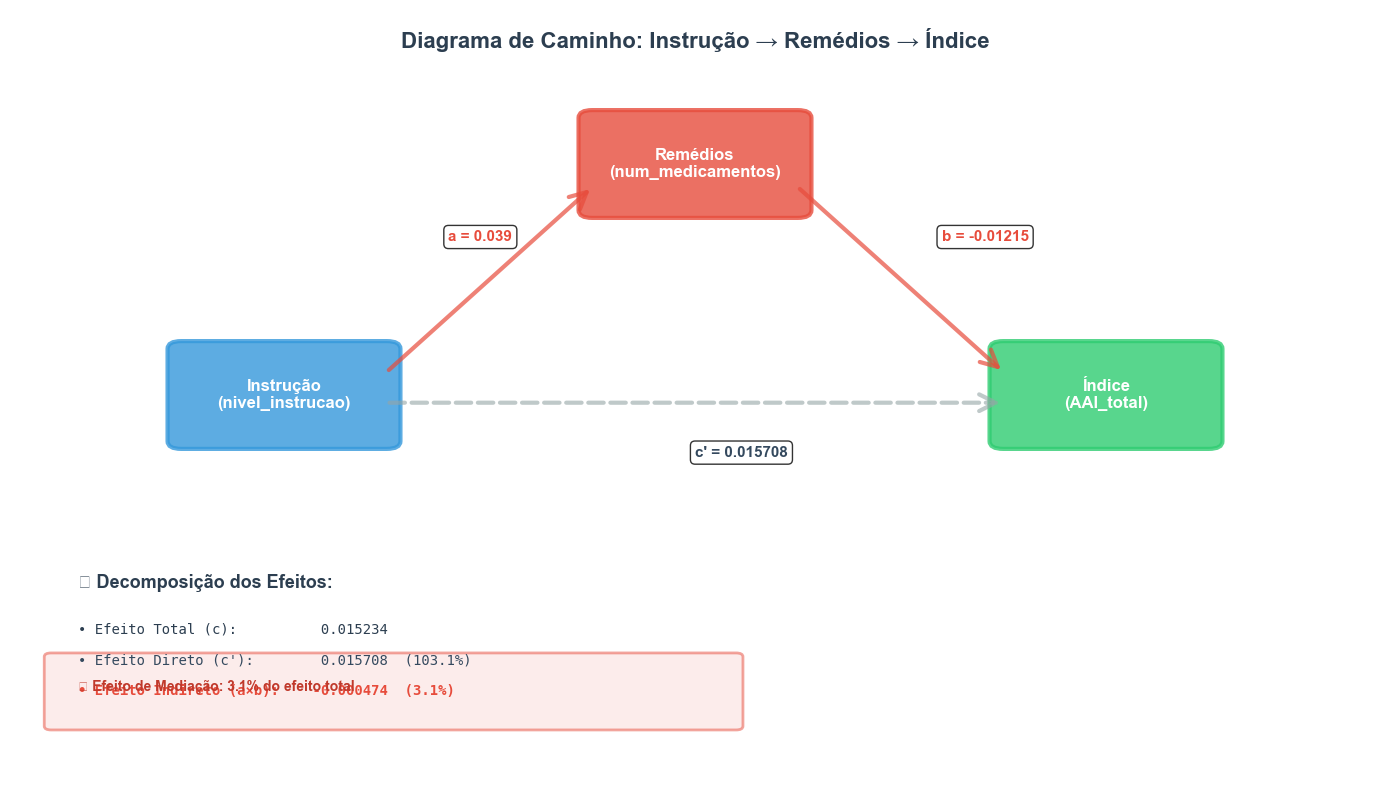


✅ Diagrama de caminho salvo em: outputs_aai/insight1_mediation_path_diagram.png


In [25]:
# ============================================================================
# VISUALIZAÇÃO 1: DIAGRAMA DE CAMINHO DA MEDIAÇÃO
# ============================================================================

from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(1, 1, figsize=(14, 8))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis('off')

# Definir posições dos nós
x_edu = 2
y_edu = 5
x_digital = 5
y_digital = 8
x_health = 8
y_health = 5

# Estilo dos nós
node_width = 1.5
node_height = 1.2
node_color_independent = '#3498db'  # Azul
node_color_mediator = '#e74c3c'     # Vermelho
node_color_dependent = '#2ecc71'    # Verde

# Desenhar nós (caixas)
# Nó: Educação (Variável Independente)
education_box = FancyBboxPatch(
    (x_edu - node_width/2, y_edu - node_height/2), 
    node_width, node_height,
    boxstyle="round,pad=0.1", 
    edgecolor=node_color_independent, 
    facecolor=node_color_independent,
    linewidth=3, alpha=0.8
)
ax.add_patch(education_box)
ax.text(x_edu, y_edu, 'Instrução\n(nivel_instrucao)', 
        ha='center', va='center', fontsize=12, fontweight='bold', color='white')

# Nó: Acesso Digital (Mediador)
digital_box = FancyBboxPatch(
    (x_digital - node_width/2, y_digital - node_height/2), 
    node_width, node_height,
    boxstyle="round,pad=0.1", 
    edgecolor=node_color_mediator, 
    facecolor=node_color_mediator,
    linewidth=3, alpha=0.8
)
ax.add_patch(digital_box)
ax.text(x_digital, y_digital, 'Remédios\n(num_medicamentos)', 
        ha='center', va='center', fontsize=12, fontweight='bold', color='white')

# Nó: Saúde (Variável Dependente)
health_box = FancyBboxPatch(
    (x_health - node_width/2, y_health - node_height/2), 
    node_width, node_height,
    boxstyle="round,pad=0.1", 
    edgecolor=node_color_dependent, 
    facecolor=node_color_dependent,
    linewidth=3, alpha=0.8
)
ax.add_patch(health_box)
ax.text(x_health, y_health, 'Índice\n(AAI_total)', 
        ha='center', va='center', fontsize=12, fontweight='bold', color='white')

# Caminhos estimados na regressão (célula de mediação)
path_a = mediation_results['path_a'].values[0]
path_b = mediation_results['path_b'].values[0]
path_c_prime = effect_direct  # Efeito direto

# Desenhar setas (caminhos)
arrow_style = "Simple, tail_width=3, head_width=12, head_length=12"

# Caminho a: Educação → Acesso Digital
arrow_a = FancyArrowPatch(
    (x_edu + node_width/2, y_edu + 0.3), 
    (x_digital - node_width/2, y_digital - 0.3),
    arrowstyle='->', mutation_scale=30, linewidth=3, 
    color='#e74c3c', alpha=0.7
)
ax.add_patch(arrow_a)
ax.text((x_edu + x_digital)/2 - 0.3, (y_edu + y_digital)/2 + 0.5, 
        f'a = {path_a:.3f}', 
        fontsize=11, fontweight='bold', color='#e74c3c',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Caminho b: Acesso Digital → Saúde
arrow_b = FancyArrowPatch(
    (x_digital + node_width/2, y_digital - 0.3), 
    (x_health - node_width/2, y_health + 0.3),
    arrowstyle='->', mutation_scale=30, linewidth=3, 
    color='#e74c3c', alpha=0.7
)
ax.add_patch(arrow_b)
ax.text((x_digital + x_health)/2 + 0.3, (y_digital + y_health)/2 + 0.5, 
        f'b = {path_b:.5f}', 
        fontsize=11, fontweight='bold', color='#e74c3c',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Caminho c': Efeito Direto (Educação → Saúde)
arrow_c_prime = FancyArrowPatch(
    (x_edu + node_width/2, y_edu - 0.1), 
    (x_health - node_width/2, y_health - 0.1),
    arrowstyle='->', mutation_scale=30, linewidth=3, 
    color='#95a5a6', alpha=0.6, linestyle='--'
)
ax.add_patch(arrow_c_prime)
ax.text((x_edu + x_health)/2, y_health - 0.8, 
        f"c' = {path_c_prime:.6f}", 
        fontsize=11, fontweight='bold', color='#34495e',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Adicionar legenda de efeitos
legend_x = 0.5
legend_y = 2.5
ax.text(legend_x, legend_y, 
        '📊 Decomposição dos Efeitos:', 
        fontsize=13, fontweight='bold', color='#2c3e50')
ax.text(legend_x, legend_y - 0.6, 
        f'• Efeito Total (c):          {effect_total:.6f}', 
        fontsize=10, color='#2c3e50', family='monospace')
ax.text(legend_x, legend_y - 1.0, 
        f"• Efeito Direto (c'):        {effect_direct:.6f}  ({(effect_direct/effect_total)*100:.1f}%)", 
        fontsize=10, color='#34495e', family='monospace')
ax.text(legend_x, legend_y - 1.4, 
        f'• Efeito Indireto (a×b):    {effect_indirect:.6f}  ({abs(percent_mediated):.1f}%)', 
        fontsize=10, color='#e74c3c', family='monospace', fontweight='bold')

# Caixa de destaque do efeito indireto
highlight_box = FancyBboxPatch(
    (legend_x - 0.2, legend_y - 1.8), 
    5, 0.9,
    boxstyle="round,pad=0.05", 
    edgecolor='#e74c3c', 
    facecolor='#fadbd8',
    linewidth=2, alpha=0.5
)
ax.add_patch(highlight_box)
ax.text(legend_x, legend_y - 1.35, 
        f'⚡ Efeito de Mediação: {abs(percent_mediated):.1f}% do efeito total', 
        fontsize=10, color='#c0392b', fontweight='bold')

# Título
ax.text(5, 9.5, 
        'Diagrama de Caminho: Instrução → Remédios → Índice', 
        ha='center', fontsize=16, fontweight='bold', color='#2c3e50')

plt.tight_layout()
plt.savefig('outputs_aai/insight1_mediation_path_diagram.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Diagrama de caminho salvo em: outputs_aai/insight1_mediation_path_diagram.png")

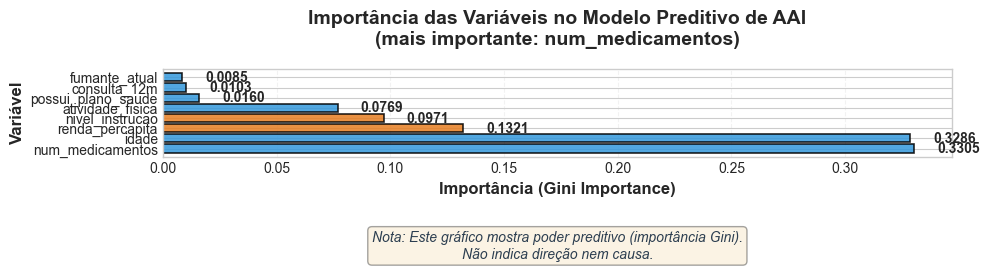

✅ Gráfico de importância salvo em: outputs_aai/insight1_feature_importance.png


In [26]:
# ============================================================================
# VISUALIZAÇÃO 2: IMPORTÂNCIA DAS VARIÁVEIS (contexto, não mediação)
# ============================================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

feature_importance = pd.read_csv('outputs_aai/feature_importance.csv')

fig, ax = plt.subplots(1, 1, figsize=(10, 6))

colors = ['#e67e22' if feat in ['nivel_instrucao', 'renda_percapita'] else '#3498db'
          for feat in feature_importance['Feature']]

bars = ax.barh(feature_importance['Feature'],
               feature_importance['Importance'],
               color=colors, alpha=0.85, edgecolor='black', linewidth=1.2)

for i, (feat, imp) in enumerate(zip(feature_importance['Feature'], feature_importance['Importance'])):
    ax.text(imp + 0.01, i, f'{imp:.4f}', va='center', fontsize=10, fontweight='bold')

ax.set_xlabel('Importância (Gini Importance)', fontsize=12, fontweight='bold')
ax.set_ylabel('Variável', fontsize=12, fontweight='bold')
ax.set_title(f'Importância das Variáveis no Modelo Preditivo de AAI\n(mais importante: {feature_importance.iloc[0]["Feature"]})',
             fontsize=14, fontweight='bold', pad=18)
ax.grid(axis='x', alpha=0.25, linestyle='--')

# Nota metodológica explícita
ax.text(0.5, -0.85,
        'Nota: Este gráfico mostra poder preditivo (importância Gini).\n'
        'Não indica direção nem causa.',
        ha='center', va='top', transform=ax.transAxes,
        fontsize=10, style='italic', color='#2c3e50',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.35))

plt.tight_layout()
plt.savefig('outputs_aai/insight1_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Gráfico de importância salvo em: outputs_aai/insight1_feature_importance.png")

### O que isso significa

O número de remédios não explica por que quem tem mais instrução tem índice maior. É uma regressão sem peso amostral e sem outros controles, então não sustenta recomendação de política.

---

## Insight 2: Diferenças entre regiões e UFs

**Pergunta:** o índice muda entre as regiões do Brasil?

Comparamos as médias ponderadas por região e as médias das 27 UFs, e fizemos uma ANOVA com as UFs agrupadas por região.

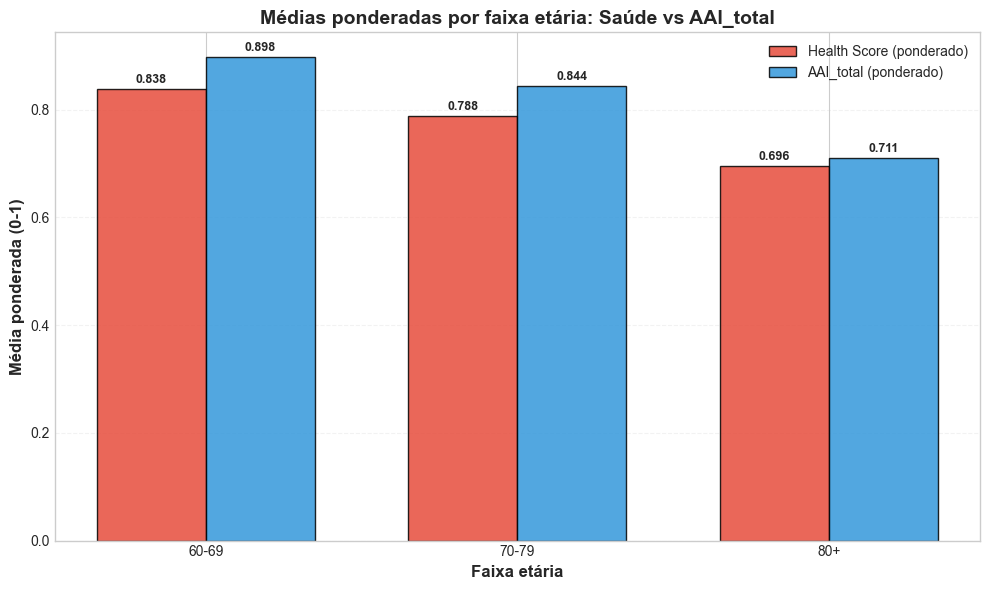

✅ Gráfico salvo em outputs_aai/idade_health_aai_weighted.png


In [27]:
# ============================================================================
# VISUAL: Médias ponderadas por faixa etária (Saúde vs AAI_total)
# ============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carregar base individual
pns = pd.read_csv('outputs_aai/pns_2019_processed_60plus.csv')

# Garantir faixas padronizadas
faixa_order = ['60-69', '70-79', '80+']

# Função de média ponderada (corrigida para lidar com NaNs)
def weighted_mean(x, w):
    x = np.asarray(x, dtype=float)
    w = np.asarray(w, dtype=float)
    mask = ~np.isnan(x) & ~np.isnan(w) & (w > 0)
    if np.sum(w[mask]) > 0:
        return np.sum(w[mask] * x[mask]) / np.sum(w[mask])
    else:
        return np.nan

agg = pns.groupby('faixa_etaria').apply(
    lambda g: pd.Series({
        'AAI_total_wmean': weighted_mean(g['AAI_total'].values, g['peso_amostral'].values),
        'health_wmean': weighted_mean(g['health_score'].values, g['peso_amostral'].values),
        'n': len(g),
        'peso_total': g['peso_amostral'].sum()
    })
).reset_index()

# Ordenar faixas
agg['faixa_etaria'] = pd.Categorical(agg['faixa_etaria'], categories=faixa_order, ordered=True)
agg = agg.sort_values('faixa_etaria')

# Plot
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
width = 0.35
x = np.arange(len(agg))

bars1 = ax.bar(x - width/2, agg['health_wmean'], width, label='Health Score (ponderado)', color='#e74c3c', alpha=0.85, edgecolor='black')
bars2 = ax.bar(x + width/2, agg['AAI_total_wmean'], width, label='AAI_total (ponderado)', color='#3498db', alpha=0.85, edgecolor='black')

for b in list(bars1) + list(bars2):
    h = b.get_height()
    ax.text(b.get_x() + b.get_width()/2, h + 0.005, f'{h:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(agg['faixa_etaria'])
ax.set_ylabel('Média ponderada (0-1)', fontsize=12, fontweight='bold')
ax.set_xlabel('Faixa etária', fontsize=12, fontweight='bold')
ax.set_title('Médias ponderadas por faixa etária: Saúde vs AAI_total', fontsize=14, fontweight='bold')
ax.legend(loc='best')
ax.grid(axis='y', alpha=0.25, linestyle='--')

plt.tight_layout()
plt.savefig('outputs_aai/idade_health_aai_weighted.png', dpi=300, bbox_inches='tight')
plt.show()

print('✅ Gráfico salvo em outputs_aai/idade_health_aai_weighted.png')

### Nota: importância não é direção

A idade é uma das variáveis mais importantes do modelo, mas a importância só diz quanto o modelo se apoia nela, não para que lado ela empurra.

O gráfico abaixo mostra as médias ponderadas por faixa etária. As duas notas caem com a idade, e o índice cai mais que a saúde (de 0,898 entre 60 e 69 anos para 0,711 aos 80 ou mais), porque a capacidade funcional cai muito depois dos 80.

In [28]:
# ============================================================================
# INSIGHT 2: DIFERENÇAS ENTRE REGIÕES E UFs
# ============================================================================

import pandas as pd
import numpy as np
from scipy import stats

uf_scores = pd.read_csv('outputs_aai/uf_scores_with_ci.csv')
aging = pd.read_csv('outputs_aai/pns_2019_processed_60plus.csv')

print("=" * 80)
print("ANÁLISE GEOGRÁFICA: Regiões e UFs")
print("=" * 80)

def weighted_mean(x, w):
    x = np.asarray(x, dtype=float)
    w = np.asarray(w, dtype=float)
    m = ~np.isnan(x) & ~np.isnan(w)
    return np.sum(w[m] * x[m]) / np.sum(w[m]) if np.sum(w[m]) > 0 else np.nan

# 1) Médias ponderadas por pessoa, por região
weighted = aging.groupby('regiao').apply(
    lambda g: pd.Series({
        'AAI_total_wmean': weighted_mean(g['AAI_total'], g['peso_amostral']),
        'health_wmean': weighted_mean(g['health_score'], g['peso_amostral']),
        'functional_wmean': weighted_mean(g['functional_score'], g['peso_amostral']),
        'n_pessoas': len(g),
        'peso_total': g['peso_amostral'].sum()
    })
).round(4)
print("\nPor região, ponderado pelo peso amostral:")
print(weighted.sort_values('AAI_total_wmean').to_string())

# 2) Médias das UFs agrupadas por região
print("\nMédia das UFs por região:")
print(uf_scores.groupby('regiao')['AAI_total'].agg(['mean', 'min', 'max', 'count']).round(4).to_string())

# 3) ANOVA entre regiões, com as UFs como unidade (27 valores)
print("\n" + "=" * 80)
print("TESTE DE HETEROGENEIDADE REGIONAL (ANOVA sobre as médias das UFs)")
print("=" * 80)
groups = [g['AAI_total'].values for _, g in uf_scores.groupby('regiao')]
f_stat, p_value = stats.f_oneway(*groups)
significance_found = p_value < 0.05
print(f"F = {f_stat:.4f} | p = {p_value:.6f}")
print("RESULTADO:", "diferenças entre regiões significativas ao nível de 5%." if significance_found
      else "diferenças entre regiões não significativas ao nível de 5%.")
print("\nNota: com só 27 UFs o teste tem pouco poder, e ele ignora a incerteza de cada média.")

ANÁLISE GEOGRÁFICA: Regiões e UFs

Por região, ponderado pelo peso amostral:
              AAI_total_wmean  health_wmean  functional_wmean  n_pessoas    peso_total
regiao                                                                                
Nordeste               0.8429        0.7919            0.8939     7736.0  8.727400e+06
Norte                  0.8630        0.8140            0.9120     3487.0  2.093277e+06
Sudeste                0.8673        0.8137            0.9210     5825.0  1.597522e+07
Sul                    0.8709        0.8120            0.9298     3307.0  5.411632e+06
Centro-Oeste           0.8745        0.8161            0.9330     2373.0  2.191319e+06

Média das UFs por região:
                mean     min     max  count
regiao                                     
Centro-Oeste  0.8759  0.8681  0.8865      4
Nordeste      0.8423  0.8240  0.8512      9
Norte         0.8680  0.8557  0.8774      7
Sudeste       0.8653  0.8547  0.8729      4
Sul           0.8721  0

In [29]:
# ============================================================================
# RESULTADO CLARO: Existe evidência estatística de diferenças regionais?
# (Apresentação dinâmica para UX — mostra 'Sim' ou 'Não' com p-value)
# ============================================================================
from IPython.display import display, HTML, Markdown

html_yes = """
<div style='background:#e8f5e9;border-left:6px solid #4caf50;padding:12px;margin:8px 0;'>
<h2 style='color:#2e7d32;margin:0;'>EVIDÊNCIA ESTATÍSTICA: SIM</h2>
<p style='margin:6px 0;'>O teste ANOVA indicou diferenças regionais estatisticamente significativas ao nível α = 0.05.</p>
<p style='margin:0;font-weight:bold;'>p-value = {p:.4f}</p>
</div>
"""

html_no = """
<div style='background:#ffebee;border-left:6px solid #d32f2f;padding:12px;margin:8px 0;'>
<h2 style='color:#c62828;margin:0;'>EVIDÊNCIA ESTATÍSTICA: NÃO</h2>
<p style='margin:6px 0;'>Não foi encontrada evidência estatística suficiente de diferenças regionais ao nível α = 0.05.</p>
<p style='margin:0;font-weight:bold;'>p-value = {p:.4f}</p>
</div>
"""

html_unknown = """
<div style='background:#fff3e0;border-left:6px solid #fb8c00;padding:12px;margin:8px 0;'>
<h2 style='color:#ef6c00;margin:0;'>EVIDÊNCIA ESTATÍSTICA: INDEFINIDA</h2>
<p style='margin:6px 0;'>Não foi possível avaliar automaticamente — as variáveis do teste (p_value / significance_found) não estão disponíveis no ambiente atual.</p>
</div>
"""

try:
    # Prefer using a boolean computed flag if available
    if 'significance_found' in globals() and 'p_value' in globals():
        if significance_found:
            display(HTML(html_yes.format(p=p_value)))
        else:
            display(HTML(html_no.format(p=p_value)))
    elif 'p_value' in globals():
        # fallback: use p_value numeric
        if float(p_value) < 0.05:
            display(HTML(html_yes.format(p=p_value)))
        else:
            display(HTML(html_no.format(p=p_value)))
    else:
        display(HTML(html_unknown))
except Exception as e:
    display(HTML(html_unknown + f"<p style='color:#666;margin-top:6px;'>Erro ao avaliar automaticamente: {str(e)}</p>"))

# Sugestões UX/seguimento (estático):
# - Se a resposta for SIM: executar testes post-hoc (Tukey/HSD) para identificar quais pares de regiões diferem.
# - Se a resposta for NÃO: considerar o poder do teste com só 27 UFs.


## Resultados da Análise Regional

- **ANOVA sobre as médias das 27 UFs:** F = 16,0, p < 0,001. As regiões diferem.
- **O Nordeste fica abaixo das outras:** média das UFs de 0,842, contra 0,865 a 0,876 nas outras regiões.
- **Cautela:** com só 27 valores e sem a incerteza de cada UF, o teste é uma indicação, não uma prova forte.


PERFIS REGIONAIS (médias ponderadas)

      regiao  AAI_total  health_score  functional_score
Centro-Oeste     0.8745        0.8161            0.9330
    Nordeste     0.8429        0.7919            0.8939
       Norte     0.8630        0.8140            0.9120
     Sudeste     0.8673        0.8137            0.9210
         Sul     0.8709        0.8120            0.9298


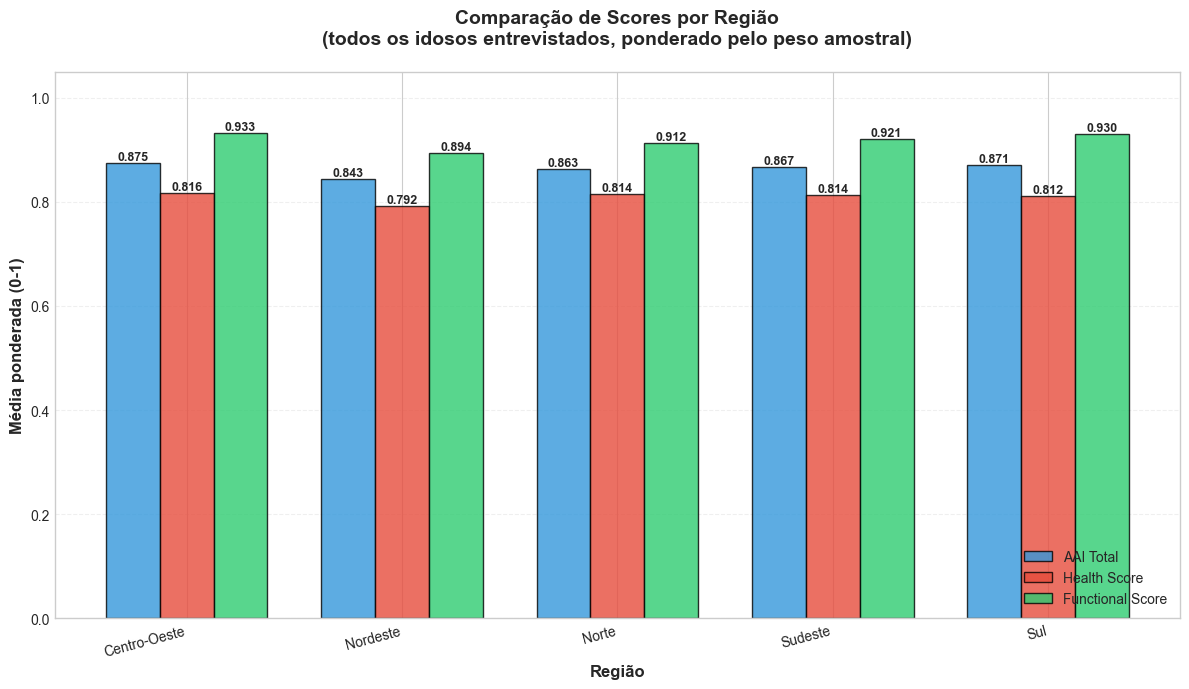


Gráfico de comparação regional salvo em: outputs_aai/insight2_regional_comparison.png


In [30]:
# ============================================================================
# VISUALIZAÇÃO 3: SCORES POR REGIÃO
# ============================================================================

regional_profiles = weighted.reset_index().rename(columns={
    'AAI_total_wmean': 'AAI_total', 'health_wmean': 'health_score', 'functional_wmean': 'functional_score'})

print("\nPERFIS REGIONAIS (médias ponderadas)\n")
print(regional_profiles[['regiao', 'AAI_total', 'health_score', 'functional_score']].to_string(index=False))

fig, ax = plt.subplots(1, 1, figsize=(12, 7))
x = np.arange(len(regional_profiles))
width = 0.25

bars1 = ax.bar(x - width, regional_profiles['AAI_total'], width, label='AAI Total', color='#3498db', alpha=0.8, edgecolor='black')
bars2 = ax.bar(x, regional_profiles['health_score'], width, label='Health Score', color='#e74c3c', alpha=0.8, edgecolor='black')
bars3 = ax.bar(x + width, regional_profiles['functional_score'], width, label='Functional Score', color='#2ecc71', alpha=0.8, edgecolor='black')

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height, f'{height:.3f}',
                ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xlabel('Região', fontsize=12, fontweight='bold')
ax.set_ylabel('Média ponderada (0-1)', fontsize=12, fontweight='bold')
ax.set_title('Comparação de Scores por Região\n(todos os idosos entrevistados, ponderado pelo peso amostral)',
             fontsize=14, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(regional_profiles['regiao'], rotation=15, ha='right')
ax.legend(loc='lower right', fontsize=10)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig('outputs_aai/insight2_regional_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nGráfico de comparação regional salvo em: outputs_aai/insight2_regional_comparison.png")

## O que isso significa

A diferença regional existe, mas é pequena na escala do índice (0,843 no Nordeste contra 0,875 no Centro-Oeste). Ela aparece tanto na nota de saúde quanto na de capacidade funcional (ver o gráfico acima).

---

## Insight 3: Como cada variável mexe no risco (SHAP)

O SHAP mostra, para cada pessoa do teste, quanto cada variável empurra para cima ou para baixo a previsão de "estar nos 20% com menor índice".

In [31]:
# ============================================================================
# INSIGHT 3: COMO CADA VARIÁVEL MEXE NO RISCO (SHAP)
# ============================================================================

shap_values_df = pd.read_csv('outputs_aai/shap_values.csv')
shap_features_df = pd.read_csv('outputs_aai/shap_features.csv')
shap_importance = pd.read_csv('outputs_aai/shap_importance.csv')
assert len(shap_values_df) == len(shap_features_df)

print("=" * 80)
print("SHAP: efeito de cada variável sobre o risco de estar nos 20% com menor índice")
print("=" * 80)
print("\nIMPORTÂNCIA SHAP DAS VARIÁVEIS\n")
print(shap_importance.to_string(index=False))
print(f"\n{len(shap_values_df)} pessoas do conjunto de teste")

SHAP: efeito de cada variável sobre o risco de estar nos 20% com menor índice

IMPORTÂNCIA SHAP DAS VARIÁVEIS

           Feature  SHAP_Importance
  num_medicamentos         0.093143
             idade         0.067967
  atividade_fisica         0.040903
   nivel_instrucao         0.036215
   renda_percapita         0.025771
possui_plano_saude         0.008241
      consulta_12m         0.006649
     fumante_atual         0.002708

1000 pessoas do conjunto de teste


## Nota técnica

Os gráficos usam os valores reais das variáveis das 1.000 pessoas do teste usadas no SHAP (`outputs_aai/shap_features.csv`). Versões anteriores usavam valores sorteados.

O SHAP descreve o modelo: mostra em que ele se apoia, não o que causa vulnerabilidade.

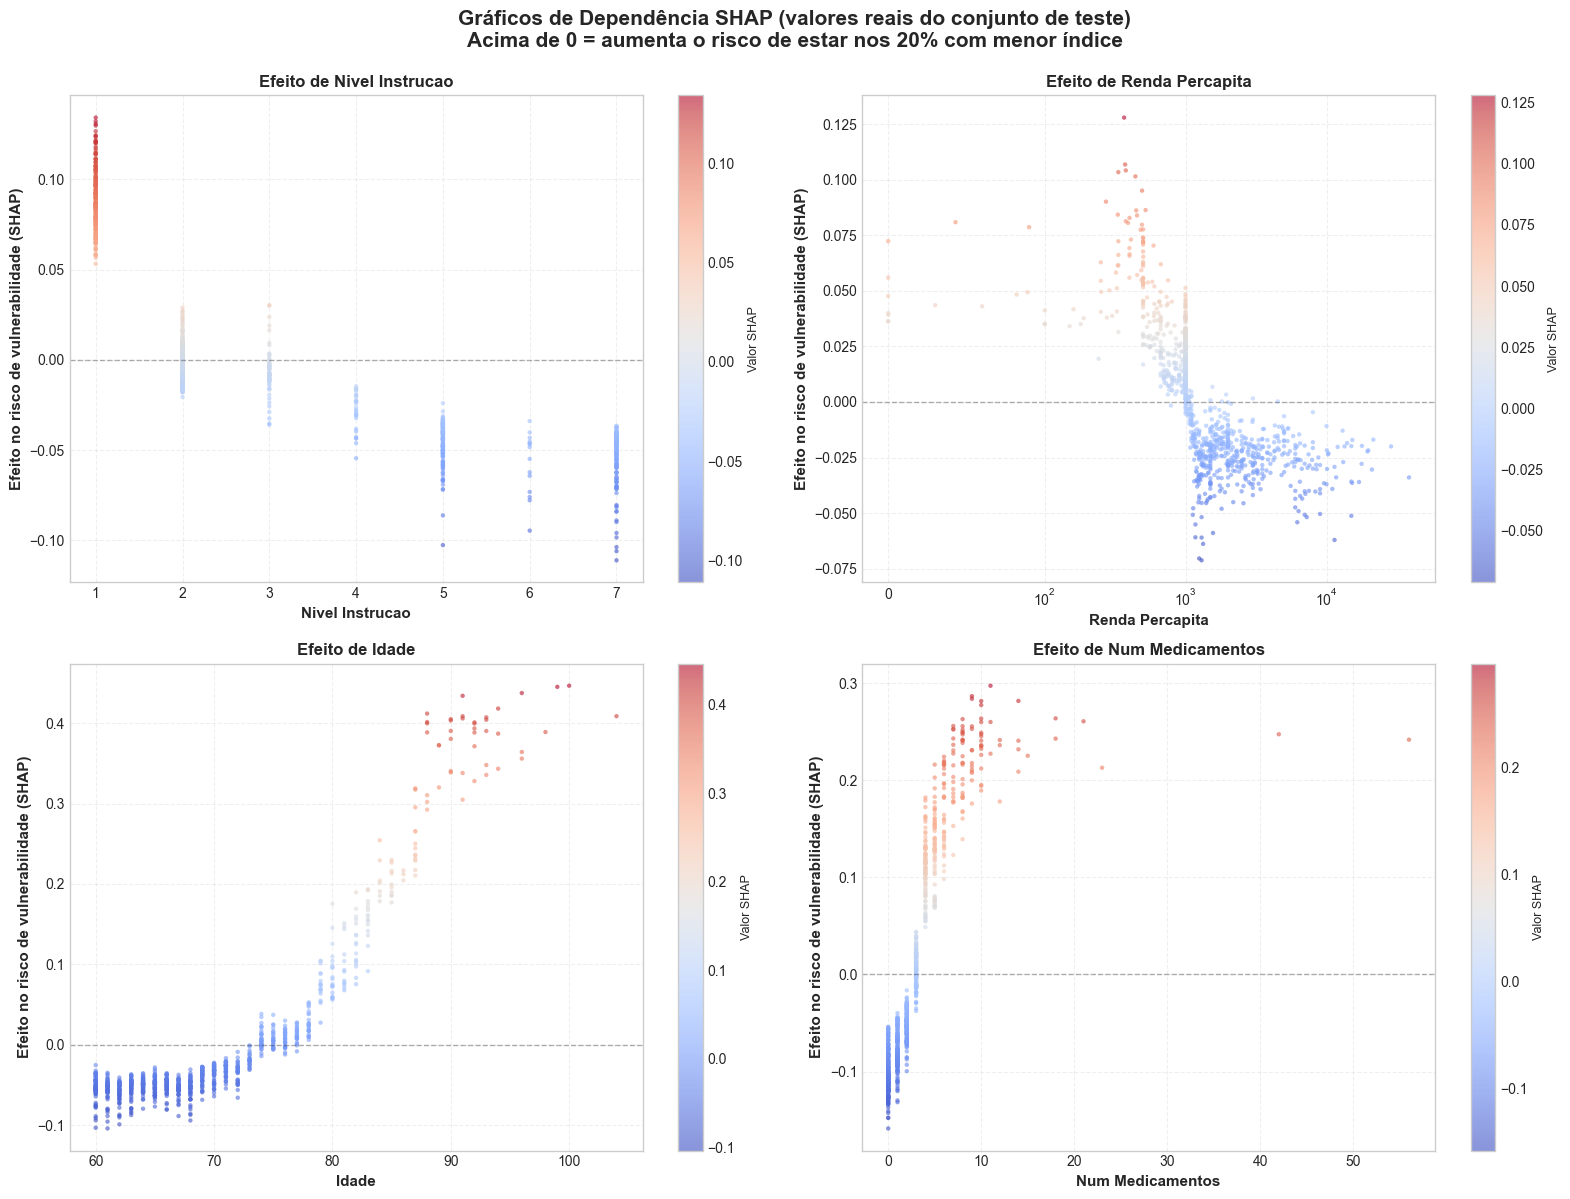


Gráficos de dependência SHAP salvos em: outputs_aai/insight3_shap_dependence_plots.png


In [32]:
# ============================================================================
# VISUALIZAÇÃO 5: GRÁFICOS DE DEPENDÊNCIA SHAP
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

shap_features = ['nivel_instrucao', 'renda_percapita', 'idade', 'num_medicamentos']

for idx, feature in enumerate(shap_features):
    ax = axes[idx]
    feature_vals = shap_features_df[feature].values
    shap_vals = shap_values_df[feature].values
    scatter = ax.scatter(feature_vals, shap_vals, c=shap_vals, cmap='coolwarm', alpha=0.6, s=10, edgecolors='none')
    if feature == 'renda_percapita':
        ax.set_xscale('symlog', linthresh=100)
    ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.3)
    ax.set_xlabel(feature.replace('_', ' ').title(), fontsize=11, fontweight='bold')
    ax.set_ylabel('Efeito no risco de vulnerabilidade (SHAP)', fontsize=11, fontweight='bold')
    ax.set_title(f'Efeito de {feature.replace("_", " ").title()}', fontsize=12, fontweight='bold')
    ax.grid(alpha=0.3, linestyle='--')
    plt.colorbar(scatter, ax=ax).set_label('Valor SHAP', fontsize=9)

fig.suptitle('Gráficos de Dependência SHAP (valores reais do conjunto de teste)\nAcima de 0 = aumenta o risco de estar nos 20% com menor índice',
             fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('outputs_aai/insight3_shap_dependence_plots.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nGráficos de dependência SHAP salvos em: outputs_aai/insight3_shap_dependence_plots.png")

In [33]:
# ============================================================================
# ANÁLISE QUANTITATIVA: EFEITO MÉDIO POR FAIXA DA VARIÁVEL
# ============================================================================

print("\n" + "=" * 80)
print("EFEITO SHAP MÉDIO POR QUARTIL DO VALOR REAL DA VARIÁVEL")
print("=" * 80)

for feature in ['nivel_instrucao', 'renda_percapita', 'idade', 'num_medicamentos']:
    faixas = pd.qcut(shap_features_df[feature], q=4, duplicates='drop')
    tabela = shap_values_df[feature].groupby(faixas, observed=True).agg(['mean', 'count'])
    tabela.columns = ['efeito_medio_shap', 'n']
    print(f"\n{feature.upper()}")
    print(tabela.round(4).to_string())
    passos = tabela['efeito_medio_shap'].diff().dropna()
    print("   Mudança entre faixas vizinhas:", ", ".join(f"{p:+.4f}" for p in passos))

print("\nLeitura: valor positivo aumenta o risco previsto. SHAP descreve o modelo, não causa.")


EFEITO SHAP MÉDIO POR QUARTIL DO VALOR REAL DA VARIÁVEL

NIVEL_INSTRUCAO
                 efeito_medio_shap    n
nivel_instrucao                        
(0.999, 2.0]                0.0267  640
(2.0, 5.0]                 -0.0321  219
(5.0, 7.0]                 -0.0555  141
   Mudança entre faixas vizinhas: -0.0589, -0.0233

RENDA_PERCAPITA
                   efeito_medio_shap    n
renda_percapita                          
(-0.001, 998.0]               0.0301  431
(998.0, 1124.5]              -0.0015   69
(1124.5, 2000.0]             -0.0236  256
(2000.0, 38500.0]            -0.0255  244
   Mudança entre faixas vizinhas: -0.0315, -0.0221, -0.0020

IDADE
                efeito_medio_shap    n
idade                                 
(59.999, 64.0]            -0.0543  293
(64.0, 68.0]              -0.0521  225
(68.0, 75.0]              -0.0244  256
(75.0, 104.0]              0.1459  226
   Mudança entre faixas vizinhas: +0.0022, +0.0277, +0.1703

NUM_MEDICAMENTOS
                  efeito_me

## Resultados por faixa

Efeito SHAP médio por quartil do valor real (positivo = mais risco):
- **Idade:** negativo até 75 anos (de −0,054 a −0,024) e sobe para +0,146 a partir dos 75.
- **Remédios:** de −0,101 (nenhum) a +0,181 (mais de 4).
- **Renda per capita:** +0,030 até R$ 998; −0,024 entre R$ 1.125 e R$ 2.000; −0,026 acima de R$ 2.000.
- **Instrução:** +0,027 até o fundamental incompleto; −0,032 do fundamental completo ao médio completo; −0,056 no superior.

Na renda e na instrução, a maior mudança está entre as faixas mais baixas. Isso sugere que, para o modelo, sair da faixa mais baixa pesa mais do que subir nas faixas altas. Descreve o modelo, não causa.

## Resumo das três análises

| Análise | O que mostra | Base |
|---|---|---|
| **1. Instrução → remédios → índice** | Caminho pequeno (3% do efeito total) e no sentido contrário | Regressões simples, IC por bootstrap |
| **2. Regiões e UFs** | Nordeste com o menor índice; as 9 UFs mais baixas são do Nordeste | Médias ponderadas, ANOVA sobre as 27 UFs |
| **3. SHAP** | Risco sobe a partir dos 75 anos e com mais de 4 remédios; maior mudança nas faixas mais baixas de renda e instrução | SHAP no conjunto de teste, com valores reais |

**Notas:**
- Importância (Gini ou SHAP) mede o quanto o modelo se apoia na variável, não a direção nem a causa.
- O número de remédios anda junto com o número de doenças, que faz parte do índice.